# Single-trial ERP estimation: N2 and P3 in `mnt_correct` trials

**Goal.** Estimate the single-trial **peak amplitude** and **peak latency** of the N2 and P3 for gradCPT
mountain trials with a correct withhold (`mnt_correct`), and compare estimators. The current approach
(`extract_comp_features` in `../modeling/model.py`) takes the argmin/argmax of the raw trial inside a fixed
window. On single trials that pick is dominated by background EEG.

**Structure of this notebook**

1. Setup, data loading (`single_subj_epoch_dict` from `eeg_epoch_subj_level`, runs combined per channel, cached)
2. Grand-average ERP and component windows
3. Shared helpers: filtering, the window-peak rule, the ground-truth simulation, and `show_method()`
4. **One section per method.** Each section explains the method, defines it, and calls `show_method()` on a demo subject:
   * (a) example trials with the estimated peak
   * (b) ERP image sorted by the estimated latency
   * (c) estimate vs ground truth in a simulation that uses this subject's real background EEG
5. Group comparison of all methods: simulation accuracy, real-data metrics, between-method agreement
6. Summary

| # | Method | Amplitude | Latency |
|---|---|---|---|
| 1 | `raw_peak` (current) | value at extreme in window | time of extreme |
| 2 | `lowpass_peak` | same, after 10 Hz low-pass | same |
| 3 | `local_peak` (Luck 2014) | local extreme exceeding ±20 ms neighbours | its time, NaN if none |
| 4 | `FAL50_meanamp` (Kiesel 2008) | mean amplitude in window | 50 % fractional-area latency |
| 5 | `wavelet_peak` (Quian Quiroga 2003) | peak of wavelet-denoised trial | its time |
| 6 | `woody` (Woody 1967) | value at aligned peak | template peak + cross-correlation lag |
| 7 | `template_MLR` (Hu/Mouraux 2010–11) | peak of template+derivative fit | its time |

## 1. Setup

In [1]:
import os, sys, gzip, pickle
import numpy as np
import pandas as pd
import pywt
from scipy.signal import butter, sosfiltfilt
from scipy.ndimage import uniform_filter1d
from scipy import stats
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def show_table(df, title, note=None):
    """Display a table with a bold title and an optional one-line explanation of its columns."""
    display(Markdown(f"**{title}**" + (f"  \n<small>{note}</small>" if note else "")))
    display(df)
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore', category=stats.ConstantInputWarning)
%matplotlib inline

code_dir = '/projectnb/nphfnirs/s/datasets/gradCPT_NN24/code/eeg/preproc_pipe'
sys.path.insert(0, code_dir)
from utils import *  # data_save_path, eeg_epoch_subj_level, mne, ...

results_dir  = os.path.join(data_save_path, "single_Subj_results", "single_trial_ERP")
cache_dir    = os.path.join(results_dir, "cache")
per_subj_dir = os.path.join(results_dir, "per_subject")
group_dir    = os.path.join(results_dir, "group")
for d in [results_dir, cache_dir, per_subj_dir, group_dir]:
    os.makedirs(d, exist_ok=True)

ch_names = ['fz', 'cz', 'pz', 'oz']
EVENT = 'mnt_correct'          # trials to estimate
NOISE_EVENT = 'city_correct'   # background-EEG pool for the simulation
OVERWRITE_CACHE = False
MIN_TRIALS = 30                # skip subjects with fewer mnt_correct trials on a primary channel
SAVE_PER_SUBJECT_FIGS = True   # per-subject example / ERP-image PNGs in per_subject/

# same epoching settings as single_Subj_analysis_ERP_ERSP.py
preproc_params = dict(epoch_reject_crit=dict(eeg=100e-6), is_detrend=1, ch_names=ch_names)

# Components. gradCPT images fade in over 800 ms, so the mountain N2/P3 are late.
# Grand average (14 subjects): N2 trough ~0.50-0.55 s at Cz/Pz, P3 peak ~0.75 s (+5.8 uV Cz, +6.6 uV Pz).
# 'primary' = channel for the simulation and most summaries;
# 'chs' = two neighbouring electrodes used for cross-channel agreement.
COMPONENTS = {
    'N2': dict(sign=-1, win=(0.42, 0.62), primary='cz', chs=('fz', 'cz')),
    'P3': dict(sign=+1, win=(0.60, 0.95), primary='cz', chs=('cz', 'pz')),
}

# estimator settings
LP_HZ = 10.0              # low-pass cut-off for lowpass/local/FAL/woody/MLR
LOCAL_PEAK_HW = 0.020     # s, half-width of the local-peak neighbourhood
FAL_FRAC = 0.5            # fractional-area latency fraction
WAV_NAME = 'bior3.3'
WAV_MAX_HZ = 15.0         # keep DWT bands whose lower edge is below this
WAV_T_THR = 2.0           # keep coefficients with |mean/SE| above this
WAV_TIME_WIN = (0.3, 1.3) # s
WOODY_MAX_LAG = 0.10      # s
WOODY_N_ITER = 10
MLR_PAD = 0.10            # s

# simulation settings
SIM_GAINS = [0.5, 1.0, 2.0, 4.0, 8.0]  # signal multiplier relative to the grand-average amplitude
SIM_N_REP = 5
SIM_AMP_CV = 0.4
SIM_LAT_SD = 0.040
SIM_LAT_CLIP = 0.100
SIM_WIDTH = {'N2': 0.035, 'P3': 0.090}
SIM_MIN_AMP = 2.0
RNG_SEED = 0

# plotting: fixed categorical order, colour follows the method everywhere
METHOD_COLORS = {
    'raw_peak':      '#2a78d6',
    'lowpass_peak':  '#eb6834',
    'local_peak':    '#1baf7a',
    'FAL50_meanamp': '#eda100',
    'wavelet_peak':  '#e87ba4',
    'woody':         '#008300',
    'template_MLR':  '#6250d6',
}
CH_COLORS = {'fz': '#2a78d6', 'cz': '#eb6834', 'pz': '#1baf7a', 'oz': '#eda100'}
INK = '#333333'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#999999', 'axes.grid': True,
                     'grid.color': '#e6e6e6', 'grid.linewidth': 0.6,
                     'font.size': 9, 'axes.titlesize': 10, 'figure.dpi': 110})

Using matplotlib as 2D backend.


## 2. Load `single_subj_epoch_dict` for every subject

For each subject: load the preprocessed EEG, run `eeg_epoch_subj_level` to get `single_subj_epoch_dict`, and
combine runs per channel. Channels can be missing in individual runs, so trials get an id `<run>_<sample>`
and are matched across channels by that id. `city_correct` trials are also kept: after their mean is
removed they provide realistic background EEG for the simulation. Results are cached in `cache/`.

In [2]:
def load_subject(key_name):
    """out[event][ch] = dict(X=(n_trials, n_times) uV, id, vtc, in_zone)."""
    cache = os.path.join(cache_dir, f"{key_name}_{EVENT}_{NOISE_EVENT}_epochs.pkl.gz")
    if os.path.exists(cache) and not OVERWRITE_CACHE:
        with gzip.open(cache, 'rb') as f:
            return pickle.load(f)
    gz_path = os.path.join(data_save_path, key_name, f"{key_name}_preprocessed_dict.pkl.gz")
    if not os.path.exists(gz_path):
        return None
    with gzip.open(gz_path, 'rb') as f:
        payload = pickle.load(f)
    single_subj_epoch_dict, single_subj_vtc_dict, _, event_labels_lookup = \
        eeg_epoch_subj_level(key_name, payload["EEG"], preproc_params)

    # in-zone / out-of-zone threshold: median VTC over all stimulus-locked events
    runs = sorted(single_subj_epoch_dict.keys())
    all_vtc = [np.asarray(single_subj_vtc_dict[r][ev]) for r in runs for ev in event_labels_lookup
               if not ev.endswith('_response') and len(single_subj_vtc_dict[r][ev]) > 0]
    if len(all_vtc) == 0:
        return None
    vtc_thres = np.median(np.concatenate(all_vtc))

    # total clean epochs at Cz over all 8 event types (subject criterion of xSubj_analysis_ERP_ERSP.py)
    n_all_cz = sum(len(e) for r in runs for e in single_subj_epoch_dict[r].values()
                   if len(e) > 0 and 'cz' in e.ch_names)
    out = dict(vtc_thres=vtc_thres, n_epochs_all_cz=n_all_cz, times=None, sfreq=None)
    for ev in [EVENT, NOISE_EVENT]:
        out[ev] = {}
        for ch in ch_names:
            Xs, ids, vtcs = [], [], []
            for r in runs:
                e = single_subj_epoch_dict[r][ev]
                if len(e) == 0 or ch not in e.ch_names:
                    continue
                if out['times'] is None:
                    out['times'], out['sfreq'] = e.times.copy(), e.info['sfreq']
                Xs.append(e.get_data(picks=ch)[:, 0] * 1e6)
                ids += [f"{r}_{s}" for s in e.events[:, 0]]
                vtcs.append(np.asarray(single_subj_vtc_dict[r][ev], dtype=float))
            if len(Xs) == 0:
                continue
            vtc = np.concatenate(vtcs)
            out[ev][ch] = dict(X=np.concatenate(Xs).astype(np.float32), id=np.array(ids),
                               vtc=vtc, in_zone=vtc < vtc_thres)
    with gzip.open(cache, 'wb') as f:
        pickle.dump(out, f)
    return out

In [3]:
subj_list = sorted(d for d in os.listdir(data_save_path)
                   if d.startswith('sub-') and os.path.isdir(os.path.join(data_save_path, d)))
excluded, subj_data = {}, {}
for key_name in tqdm(subj_list, desc='loading'):
    try:
        D = load_subject(key_name)
    except Exception as err:
        excluded[key_name] = f"loading/epoching failed: {err!r}"
        continue
    if D is None:
        excluded[key_name] = "preprocessed dict missing or no valid trials"
        continue
    n_min = min(len(D[EVENT].get(c['primary'], {}).get('X', [])) for c in COMPONENTS.values())
    if n_min < MIN_TRIALS:
        excluded[key_name] = f"fewer than {MIN_TRIALS} {EVENT} trials on a primary channel ({n_min})"
        continue
    subj_data[key_name] = D

t = next(iter(subj_data.values()))['times']
sfreq = next(iter(subj_data.values()))['sfreq']
n_trials_tbl = pd.DataFrame({k: {ch: len(D[EVENT][ch]['X']) if ch in D[EVENT] else 0 for ch in ch_names}
                             for k, D in subj_data.items()}).T
print(f"{len(subj_data)} subjects kept, {len(excluded)} excluded; sfreq = {sfreq} Hz, "
      f"epoch {t[0]:.2f} to {t[-1]:.2f} s")
show_table(pd.Series(excluded, name='reason').to_frame(),
           'Table 2.1 - Excluded subjects and the reason',
           f'Subjects without a preprocessed dict, or with fewer than {MIN_TRIALS} {EVENT} trials on a primary channel.')
show_table(n_trials_tbl.describe().round(0),
           f'Table 2.2 - Number of clean {EVENT} trials per channel (summary over kept subjects)',
           'count = number of subjects; other rows = distribution of trial counts across subjects.')

loading:   0%|          | 0/31 [00:00<?, ?it/s]

loading:  39%|███▊      | 12/31 [00:00<00:00, 97.20it/s]

loading:  71%|███████   | 22/31 [00:00<00:00, 21.44it/s]

/projectnb/nphfnirs/s/datasets/gradCPT_NN24/code/eeg/preproc_pipe/utils.py:82: RuntimeWarning: No coordinate information found for channels ['Trigger', 'tp9h', 'tp10h', 'hEOG', 'vEOG']. Setting channel types to misc. To avoid this warning, set channel types explicitly.
  raw = mne.io.read_raw_brainvision(tmp_path, preload=preload, verbose=False)


/projectnb/nphfnirs/s/datasets/gradCPT_NN24/code/eeg/preproc_pipe/utils.py:82: RuntimeWarning: Not setting positions of 5 misc channels found in montage:
['Trigger', 'tp9h', 'tp10h', 'hEOG', 'vEOG']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_brainvision(tmp_path, preload=preload, verbose=False)


/projectnb/nphfnirs/s/datasets/gradCPT_NN24/code/eeg/preproc_pipe/utils.py:388: RuntimeWarning: All epochs were dropped!
You might need to alter reject/flat-criteria or drop bad channels to avoid this. You can use Epochs.plot_drop_log() to see which channels are responsible for the dropping of epochs.
  epochs = mne.Epochs(EEG, events=events_filtered,event_id={select_event:event_labels_lookup[select_event]},preload=True,
/projectnb/nphfnirs/s/datasets/gradCPT_NN24/code/eeg/preproc_pipe/utils.py:388: RuntimeWarning: All epochs were dropped!
You might need to alter reject/flat-criteria or drop bad channels to avoid this. You can use Epochs.plot_drop_log() to see which channels are responsible for the dropping of epochs.
  epochs = mne.Epochs(EEG, events=events_filtered,event_id={select_event:event_labels_lookup[select_event]},preload=True,
/projectnb/nphfnirs/s/datasets/gradCPT_NN24/code/eeg/preproc_pipe/utils.py:388: RuntimeWarning: All epochs were dropped!
You might need to alter rejec

... (4 outputs left out)

**Table 2.1 - Excluded subjects and the reason**  
<small>Subjects without a preprocessed dict, or with fewer than 30 mnt_correct trials on a primary channel.</small>

,reason
sub-629,preprocessed dict missing or no valid trials
sub-634,preprocessed dict missing or no valid trials
sub-636,preprocessed dict missing or no valid trials
sub-637,preprocessed dict missing or no valid trials
sub-642,preprocessed dict missing or no valid trials
sub-643,preprocessed dict missing or no valid trials
sub-656,preprocessed dict missing or no valid trials
sub-659,preprocessed dict missing or no valid trials
sub-661,preprocessed dict missing or no valid trials
sub-662,preprocessed dict missing or no valid trials


**Table 2.2 - Number of clean mnt_correct trials per channel (summary over kept subjects)**  
<small>count = number of subjects; other rows = distribution of trial counts across subjects.</small>

,fz,cz,pz,oz
count,14.0,14.0,14.0,14.0
mean,81.0,89.0,89.0,87.0
std,22.0,21.0,21.0,23.0
min,39.0,57.0,57.0,50.0
25%,70.0,72.0,72.0,71.0
50%,80.0,84.0,84.0,84.0
75%,91.0,105.0,105.0,105.0
max,119.0,127.0,127.0,127.0


### 2.1 ERP: city vs mountain (sanity check, replicates *Analysis 2* of `xSubj_analysis_ERP_ERSP.py`)

This section reproduces the cross-subject city vs mountain ERP to check that the epochs are correct before
any single-trial work. It uses the same subject criterion as the xSubj script: clean epochs at Cz over all 8
event types must be at least 50 % of the 2700 target. Each subject's average ERP is computed, then the mean
± 2 SEM across subjects is plotted (the xSubj convention, with SEM using `np.std`, ddof = 0). Mountain trials
should show a clear P3 at Cz. The reference figure from `xSubj_analysis_ERP_ERSP.py` is shown below for
comparison. Note that the reference is in V and this figure is in µV.

**Table 2.3 - Subject criterion of xSubj_analysis_ERP_ERSP.py**  
<small>n_epochs_all_cz = clean epochs at Cz over all 8 event types; kept if >= 50% of 2700. 14 of 14 subjects kept for this figure.</small>

,n_epochs_all_cz,kept_for_city_vs_mnt
sub-670,2681,True
sub-671,2211,True
sub-673,2129,True
sub-695,2676,True
sub-721,2700,True
sub-723,2613,True
sub-726,1474,True
sub-730,2686,True
sub-746,2393,True
sub-751,2583,True


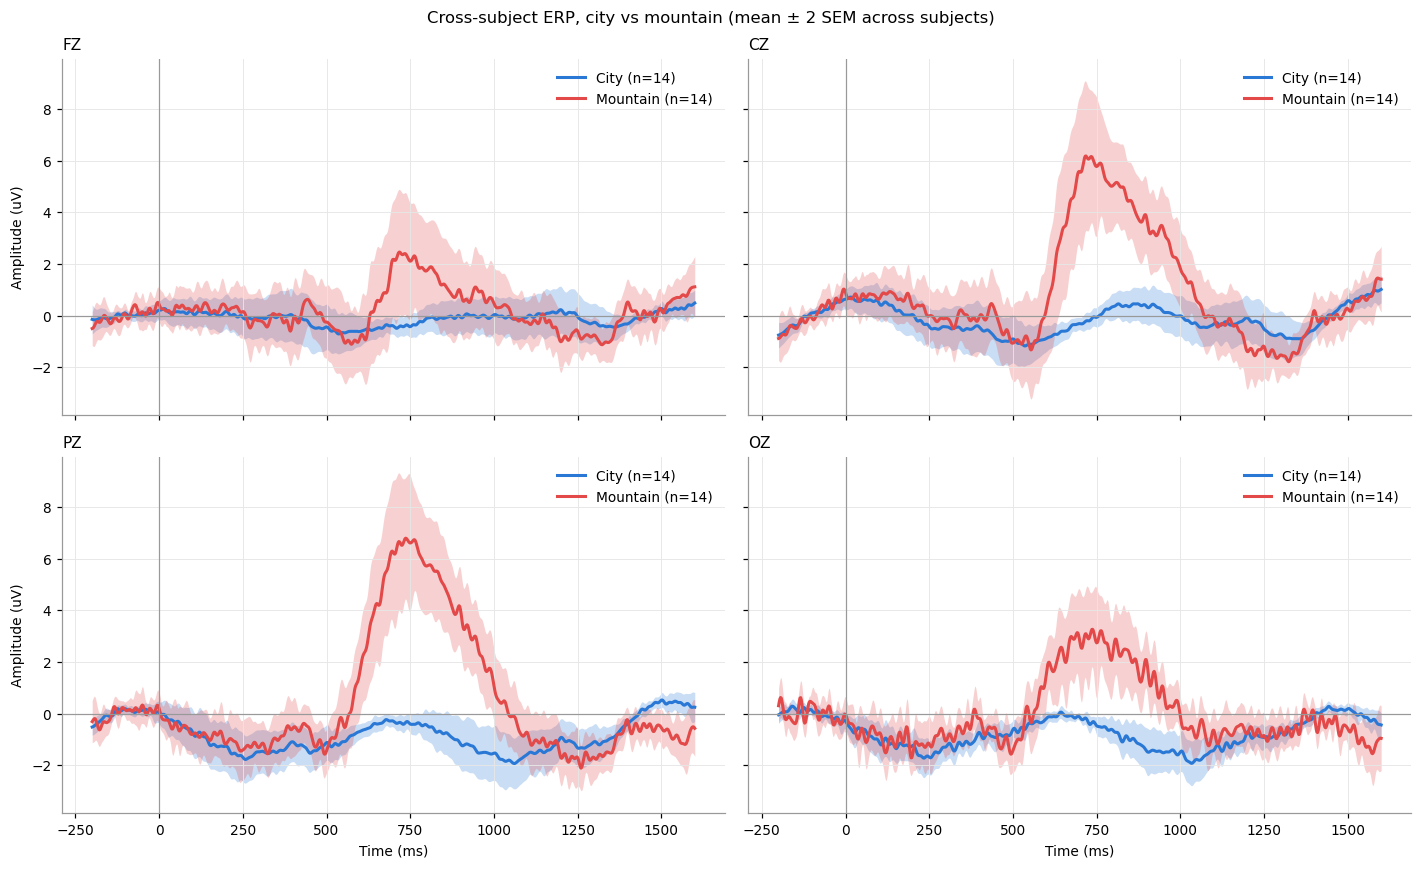

**Reference: xSubj_analysis_ERP_ERSP.py, Cz** (`/projectnb/nphfnirs/s/datasets/gradCPT_NN24/derivatives/eeg/xSubj_results/ERP_city_vs_mnt/xSubj_ERP_city_vs_mnt_cz.png`)

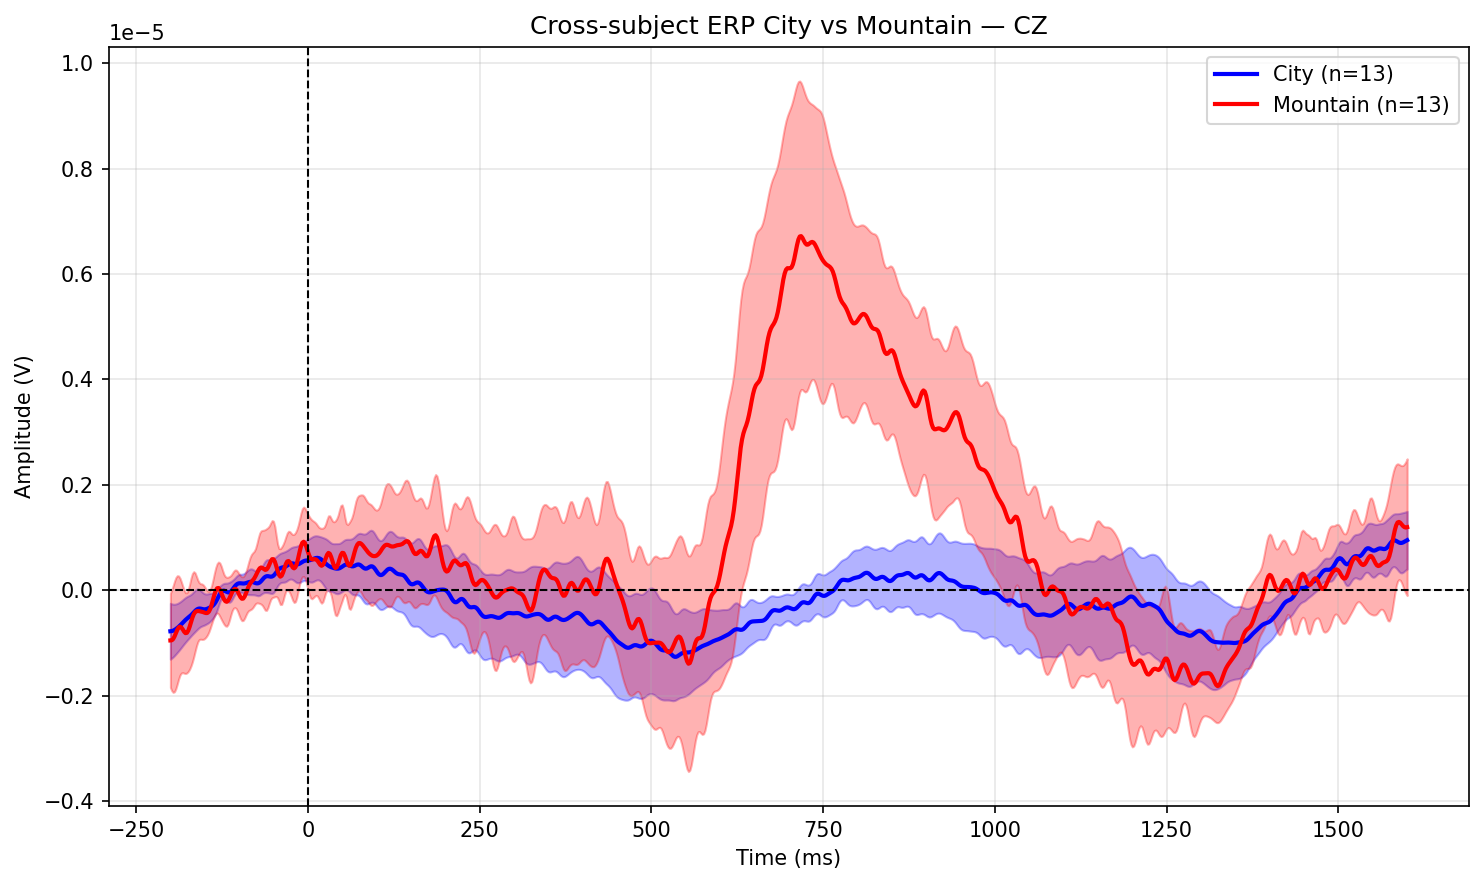

In [4]:
XSUBJ_TARGET = 2700  # 450 epochs x 3 runs x 2 time-locks
xsubj_keep = [k for k, D in subj_data.items() if D['n_epochs_all_cz'] >= 0.5 * XSUBJ_TARGET]
show_table(pd.DataFrame({'n_epochs_all_cz': {k: D['n_epochs_all_cz'] for k, D in subj_data.items()},
                         'kept_for_city_vs_mnt': {k: k in xsubj_keep for k in subj_data}}),
           'Table 2.3 - Subject criterion of xSubj_analysis_ERP_ERSP.py',
           f'n_epochs_all_cz = clean epochs at Cz over all 8 event types; kept if >= 50% of {XSUBJ_TARGET}. '
           f'{len(xsubj_keep)} of {len(subj_data)} subjects kept for this figure.')

cond_style = {'city_correct': ('City', '#2a78d6'), 'mnt_correct': ('Mountain', '#e34948')}
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True)
for ax, ch in zip(axes.ravel(), ch_names):
    for ev in ['city_correct', 'mnt_correct']:
        erps = np.vstack([subj_data[k][ev][ch]['X'].mean(0) for k in xsubj_keep if ch in subj_data[k][ev]])
        m, se = erps.mean(0), erps.std(0) / np.sqrt(len(erps))
        lab, col = cond_style[ev]
        ax.plot(t * 1000, m, color=col, lw=2, label=f"{lab} (n={len(erps)})")
        ax.fill_between(t * 1000, m - 2 * se, m + 2 * se, color=col, alpha=0.25, lw=0)
    ax.axhline(0, color='#999999', lw=0.8); ax.axvline(0, color='#999999', lw=0.8)
    ax.set_title(f"{ch.upper()}", loc='left')
    ax.legend(frameon=False, loc='upper right')
for ax in axes[-1]: ax.set_xlabel('Time (ms)')
for ax in axes[:, 0]: ax.set_ylabel('Amplitude (uV)')
fig.suptitle('Cross-subject ERP, city vs mountain (mean ± 2 SEM across subjects)')
fig.tight_layout()
fig.savefig(os.path.join(group_dir, "xSubj_ERP_city_vs_mnt.png"), dpi=150, bbox_inches='tight')
plt.show()

# reference figure produced by xSubj_analysis_ERP_ERSP.py
from IPython.display import Image
ref_png = os.path.join(data_save_path, 'xSubj_results', 'ERP_city_vs_mnt', 'xSubj_ERP_city_vs_mnt_cz.png')
if os.path.exists(ref_png):
    display(Markdown(f"**Reference: xSubj_analysis_ERP_ERSP.py, Cz** (`{ref_png}`)"))
    display(Image(filename=ref_png, width=750))


## 3. Grand average, component windows, and single-trial SNR

The windows are chosen from the grand average (shaded). The table compares the average ERP size with the
trial-to-trial SD of the background EEG; that ratio is the single-trial SNR every method has to deal with.

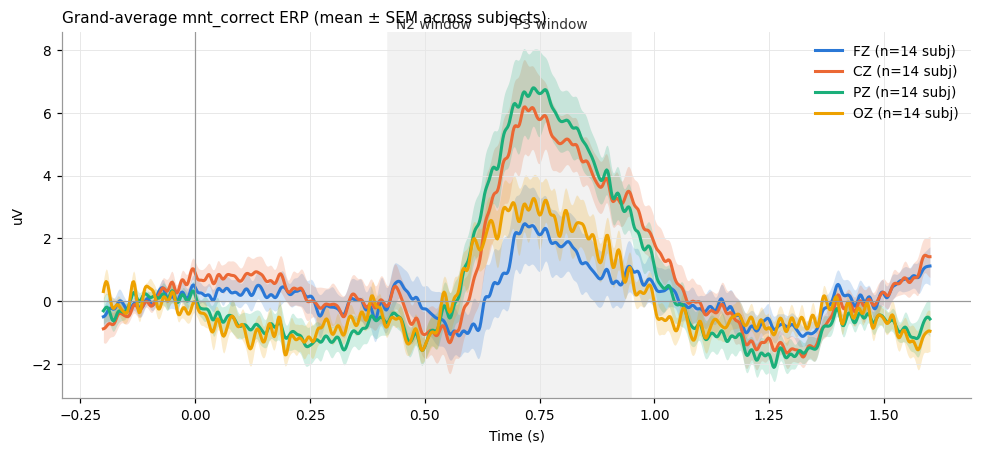

In [5]:
ga_rows = {ch: [D[EVENT][ch]['X'].mean(0) for D in subj_data.values() if ch in D[EVENT]] for ch in ch_names}

fig, ax = plt.subplots(figsize=(9, 4.2))
for cname, comp in COMPONENTS.items():
    ax.axvspan(*comp['win'], color='#f2f2f2', zorder=0)
    ax.text(np.mean(comp['win']), 1.0, f"{cname} window", transform=ax.get_xaxis_transform(),
            ha='center', va='bottom', color=INK)
for ch in ch_names:
    A = np.vstack(ga_rows[ch])
    m, se = A.mean(0), A.std(0, ddof=1) / np.sqrt(len(A))
    ax.plot(t, m, color=CH_COLORS[ch], lw=2, label=f"{ch.upper()} (n={len(A)} subj)")
    ax.fill_between(t, m - se, m + se, color=CH_COLORS[ch], alpha=0.2, lw=0)
ax.axhline(0, color='#999999', lw=0.8); ax.axvline(0, color='#999999', lw=0.8)
ax.set_xlabel('Time (s)'); ax.set_ylabel('uV')
ax.set_title(f"Grand-average {EVENT} ERP (mean ± SEM across subjects)", loc='left')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(os.path.join(group_dir, "grand_average_ERP.png"), dpi=150, bbox_inches='tight')
plt.show()

In [6]:
def lowpass(X, sfreq, hz=LP_HZ, order=4):
    sos = butter(order, hz, btype='low', fs=sfreq, output='sos')
    return sosfiltfilt(sos, X, axis=-1)

def _win_idx(t, win):
    return np.where((t >= win[0]) & (t <= win[1]))[0]

# simulation amplitudes/latencies taken from the grand average
sim_params, snr_rows = {}, []
for cname, comp in COMPONENTS.items():
    ga_lp = lowpass(np.vstack(ga_rows[comp['primary']]).mean(0)[None], sfreq)[0]
    idx = _win_idx(t, comp['win'])
    k = (comp['sign'] * ga_lp[idx]).argmax()
    amp = max(SIM_MIN_AMP, abs(ga_lp[idx][k]))  # baseline-corrected grand-average peak
    sim_params[cname] = dict(amp=comp['sign'] * amp, lat=t[idx][k], width=SIM_WIDTH[cname])
    # per-subject: |average ERP peak| vs single-trial SD in the window
    for key_name, D in subj_data.items():
        X = D[EVENT][comp['primary']]['X'].astype(float)
        erp = lowpass(X.mean(0)[None], sfreq)[0][idx]
        snr_rows.append(dict(component=cname, subject=key_name,
                             erp_peak_uV=(comp['sign'] * erp).max() * comp['sign'],
                             trial_sd_uV=(X[:, idx] - X[:, idx].mean(0)).std(),
                             trial_sd_lp_uV=(lowpass(X, sfreq)[:, idx] - lowpass(X, sfreq)[:, idx].mean(0)).std()))
snr_df = pd.DataFrame(snr_rows)
snr_df['single_trial_SNR'] = snr_df.erp_peak_uV.abs() / snr_df.trial_sd_lp_uV
show_table(pd.DataFrame(sim_params).T,
           'Table 3.1 - Simulation parameters of the synthetic N2 / P3 (taken from the grand average)',
           'amp = mean component amplitude (uV, signed) at gain 1; lat = mean peak latency (s); width = Gaussian SD (s).')
show_table(snr_df.groupby('component')[['erp_peak_uV', 'trial_sd_uV', 'trial_sd_lp_uV', 'single_trial_SNR']].median().round(2),
           'Table 3.2 - Single-trial SNR per component (median over subjects, primary channel)',
           'erp_peak_uV = peak of the subject-average ERP in the window; trial_sd(_lp)_uV = SD of single trials around the average (raw / 10 Hz low-passed); single_trial_SNR = |erp_peak| / trial_sd_lp.')

**Table 3.1 - Simulation parameters of the synthetic N2 / P3 (taken from the grand average)**  
<small>amp = mean component amplitude (uV, signed) at gain 1; lat = mean peak latency (s); width = Gaussian SD (s).</small>

,amp,lat,width
N2,-2.000000,0.54,0.035
P3,6.070865,0.73,0.090


**Table 3.2 - Single-trial SNR per component (median over subjects, primary channel)**  
<small>erp_peak_uV = peak of the subject-average ERP in the window; trial_sd(_lp)_uV = SD of single trials around the average (raw / 10 Hz low-passed); single_trial_SNR = |erp_peak| / trial_sd_lp.</small>

,erp_peak_uV,trial_sd_uV,trial_sd_lp_uV,single_trial_SNR
component,,,,
N2,-2.33,13.04,11.96,0.18
P3,7.80,12.29,11.24,0.76


## 4. Shared helpers

* `window_peak`: largest deflection of the component's polarity inside the window. A peak that lands on the
  window border is flagged `edge`, because it means there is no real peak inside the window.
* `simulate`: synthetic N2 and P3 (Gaussians, random amplitude CV 0.4, latency jitter SD 40 ms, independent
  for N2 and P3) added to real background EEG: this subject's `city_correct` trials with their mean removed,
  using the subject's real `mnt_correct` trial count. The simulated component sizes match the grand average,
  and `gain` scales them. Template-based methods build their templates from the simulated trials, as they
  would on real data.
* `show_method(name)` makes the three demo panels for one method on the demo subject.

**How to read the sorted ERP image:** sorting by *any* peak-picking estimate produces a diagonal band, even
on pure noise, because the band is wherever the maximum happened to fall. The ERP image is therefore a
visual check only. The simulation is the real test.

In [7]:
def window_peak(Y, t, comp):
    idx = _win_idx(t, comp['win'])
    k = (comp['sign'] * Y[:, idx]).argmax(1)
    return dict(amp=Y[np.arange(len(Y)), idx[k]], lat=t[idx[k]],
                edge=(k == 0) | (k == len(idx) - 1))

def simulate(noise_pool, t, n_trials, true_params, gain, rng):
    sel = rng.choice(len(noise_pool), n_trials, replace=len(noise_pool) < n_trials)
    X = noise_pool[sel].astype(float).copy()
    truth = {}
    for name, p in true_params.items():
        a = p['amp'] * gain * np.clip(rng.normal(1, SIM_AMP_CV, n_trials), 0, None)
        lat = p['lat'] + np.clip(rng.normal(0, SIM_LAT_SD, n_trials), -SIM_LAT_CLIP, SIM_LAT_CLIP)
        X += a[:, None] * np.exp(-0.5 * ((t[None, :] - lat[:, None]) / p['width']) ** 2)
        truth[name] = dict(amp=a, lat=lat)
    return X, truth

def noise_pool_of(D, ch):
    noise = D[NOISE_EVENT][ch]['X'].astype(float)
    return noise - noise.mean(0, keepdims=True)

def _r(a, b):
    m = np.isfinite(a) & np.isfinite(b)
    if m.sum() < 5 or np.std(a[m]) == 0 or np.std(b[m]) == 0:
        return np.nan
    return stats.pearsonr(a[m], b[m])[0]

def _fisher_mean(r):
    return np.tanh(np.nanmean(np.arctanh(np.clip(np.asarray(r, float), -0.999, 0.999))))

def cohens_d(x, mask):
    a, b = x[mask], x[~mask]
    a, b = a[np.isfinite(a)], b[np.isfinite(b)]
    if len(a) < 3 or len(b) < 3:
        return np.nan
    sp = np.sqrt(((len(a) - 1) * a.var(ddof=1) + (len(b) - 1) * b.var(ddof=1)) / (len(a) + len(b) - 2))
    return (a.mean() - b.mean()) / sp

METHODS = {}  # filled method by method below

# demo subject: the one with the most trials on the P3 primary channel
demo_subj = max(subj_data, key=lambda k: len(subj_data[k][EVENT][COMPONENTS['P3']['primary']]['X']))
print("demo subject:", demo_subj, {c: len(subj_data[demo_subj][EVENT][COMPONENTS[c]['primary']]['X']) for c in COMPONENTS})

COMP_COLORS = {'N2': '#2a78d6', 'P3': '#eb6834'}  # component identity in the example-trial row

def show_method(mname, subj=demo_subj, n_show=3, demo_gains=(1.0, 4.0), seed=0):
    """(a) example trials, (b) latency-sorted ERP image, (c) simulation estimate vs truth."""
    f = METHODS[mname]
    col = METHOD_COLORS[mname]
    D = subj_data[subj]
    rng = np.random.default_rng(seed)
    fig = plt.figure(figsize=(15, 9.5))
    gs = fig.add_gridspec(3, 6, height_ratios=[1, 1.1, 1.1], hspace=0.55, wspace=0.45)
    sim_summary = []
    # (a) example trials: the same trials in all 6 panels show both the N2 and the P3 estimate
    top_ch = COMPONENTS['P3']['primary']
    assert all(c['primary'] == top_ch for c in COMPONENTS.values()), "top row assumes one shared primary channel"
    Xtop = D[EVENT][top_ch]['X'].astype(float)
    Ytop = lowpass(Xtop, sfreq)
    res_top = {cname: f(Xtop, t, sfreq, comp) for cname, comp in COMPONENTS.items()}
    trials = np.sort(rng.choice(len(Xtop), 2 * n_show, replace=False))
    for j, tr in enumerate(trials):
        ax = fig.add_subplot(gs[0, j])
        ax.plot(t, Xtop[tr], color='#c8c8c8', lw=0.7, label='raw')
        ax.plot(t, Ytop[tr], color=INK, lw=1.3, label=f'{LP_HZ:g} Hz low-pass')
        for cname, comp in COMPONENTS.items():
            cc = COMP_COLORS[cname]
            ax.axvspan(*comp['win'], color=cc, alpha=0.08, lw=0, zorder=0)
            r_ = res_top[cname]
            if np.isfinite(r_['lat'][tr]):
                ax.plot(r_['lat'][tr], r_['amp'][tr], 'o', ms=8, color=cc, mec='white', mew=1.5,
                        zorder=5, label=f'{cname} peak')
        ax.set_xlim(0.2, 1.4)
        ax.set_title(f"{top_ch.upper()} trial {tr}", loc='left', fontsize=8)
        if j == 0: ax.set_ylabel('uV')
    from matplotlib.lines import Line2D
    h = [Line2D([], [], color='#c8c8c8', lw=0.7), Line2D([], [], color=INK, lw=1.3)] + \
        [Line2D([], [], ls='none', marker='o', ms=8, color=COMP_COLORS[c_], mec='white', mew=1.5) for c_ in COMPONENTS]
    l = ['raw', f'{LP_HZ:g} Hz low-pass'] + [f'{c_} peak ({mname})' for c_ in COMPONENTS]
    fig.legend(h, l, loc='upper right', bbox_to_anchor=(0.99, 0.975), ncol=4, fontsize=8, frameon=False)
    for c_i, (cname, comp) in enumerate(COMPONENTS.items()):
        ch = comp['primary']
        X = D[EVENT][ch]['X'].astype(float)
        res = f(X, t, sfreq, comp)
        Ylp = lowpass(X, sfreq)
        # (b) sorted ERP image
        ax = fig.add_subplot(gs[1, c_i * 3:c_i * 3 + 3])
        n = len(X)
        order = np.argsort(np.where(np.isfinite(res['lat']), res['lat'], np.inf))
        img = uniform_filter1d(Ylp[order], size=max(3, int(round(0.05 * n))), axis=0, mode='nearest')
        clim = np.nanpercentile(np.abs(Ylp[:, (t > 0) & (t < 1.4)]), 90)
        im = ax.imshow(img, aspect='auto', origin='lower', cmap='RdBu_r', vmin=-clim, vmax=clim,
                       extent=[t[0], t[-1], 0, n], interpolation='nearest')
        ax.plot(res['lat'][order], np.arange(n) + 0.5, color=INK, lw=1)
        for w in comp['win']:
            ax.axvline(w, color=INK, lw=0.6, ls=':')
        ax.grid(False); ax.set_xlim(0, 1.4)
        ax.set_xlabel('Time (s)'); ax.set_ylabel('Trial (sorted by latency)')
        ax.set_title(f"{cname}: ERP image sorted by {mname} latency "
                     f"(edge/no-peak {np.mean(res['edge'])*100:.0f}%)", loc='left')
        fig.colorbar(im, ax=ax, shrink=0.8, label='uV')
        # (c) simulation: estimate vs truth, latency and amplitude, for two gains
        sim_rng = np.random.default_rng(RNG_SEED)
        noise = noise_pool_of(D, ch)
        for g_i, gain in enumerate(demo_gains):
            Xs, truth = simulate(noise, t, n, sim_params, gain, sim_rng)
            est = f(Xs, t, sfreq, comp)
            tr_ = truth[cname]
            for q_i, (q, scale, unit) in enumerate([('lat', 1000, 'ms'), ('amp', 1, 'uV')]):
                if q == 'amp' and g_i == 1:
                    continue
                pos = c_i * 3 + (g_i if q == 'lat' else 2)
                ax = fig.add_subplot(gs[2, pos])
                ax.plot(tr_[q] * scale, est[q] * scale, 'o', ms=4, color=col, alpha=0.6, mec='none')
                lims = np.nanpercentile(np.r_[tr_[q], est[q]] * scale, [1, 99])
                ax.plot(lims, lims, color='#999999', lw=0.8, ls='--')
                r = _r(est[q], tr_[q])
                ax.set_title(f"{cname} {q}, gain {gain:g}: r={r:.2f}", loc='left', fontsize=8)
                ax.set_xlabel(f'true ({unit})', fontsize=8)
                if pos % 3 == 0: ax.set_ylabel(f'estimated', fontsize=8)
                if q == 'lat':
                    sim_summary.append(dict(component=cname, gain=gain, r_lat=r,
                                            rmse_lat_ms=np.sqrt(np.nanmean((est['lat'] - tr_['lat'])**2)) * 1000,
                                            r_amp=_r(est['amp'], tr_['amp'])))
    fig.suptitle(f"{mname} on {subj}: (top) example trials with N2/P3 peaks; "
                 f"(middle) latency-sorted ERP image; (bottom) simulation, estimate vs truth", y=0.995)
    fig.savefig(os.path.join(group_dir, f"method_demo_{mname}.png"), dpi=130, bbox_inches='tight')
    plt.show()
    show_table(pd.DataFrame(sim_summary).round(3),
               f'{mname} - simulation accuracy on {subj} (one simulated data set per gain)',
               'r_lat / r_amp = Pearson r between estimated and true single-trial latency / amplitude (1 = perfect, 0 = chance); '
               f'rmse_lat_ms = latency error (a constant guess gives about {SIM_LAT_SD*1000:.0f} ms).')

demo subject: sub-670 {'N2': 127, 'P3': 127}


## 5. Methods, one by one

### 5.1 `raw_peak`: window peak on the raw trial (current method)

This is the argmax/argmin of the unfiltered trial inside the component window. It is simple and makes no
assumptions, but it is the most noise-sensitive estimator. High-frequency noise and alpha ride on the trial,
so the pick often lands on a noise spike, and the amplitude estimate is biased away from zero (the maximum of
noise is always large). Its latency distribution is squeezed toward wherever the noise peaks, often the window edges.

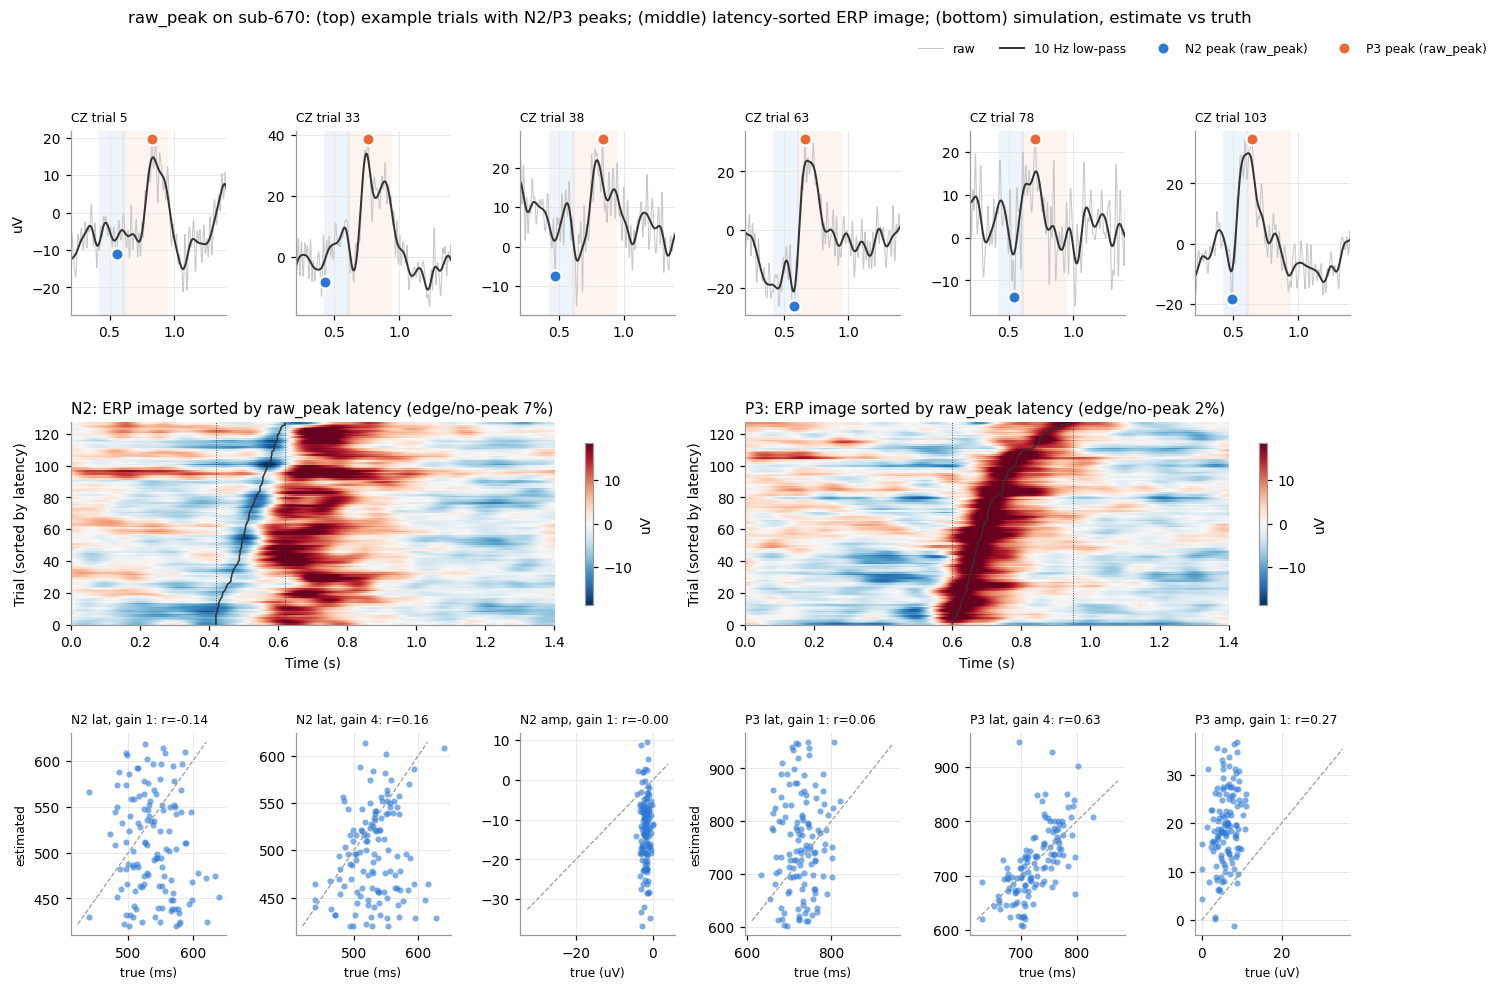

**raw_peak - simulation accuracy on sub-670 (one simulated data set per gain)**  
<small>r_lat / r_amp = Pearson r between estimated and true single-trial latency / amplitude (1 = perfect, 0 = chance); rmse_lat_ms = latency error (a constant guess gives about 40 ms).</small>

,component,gain,r_lat,rmse_lat_ms,r_amp
0,N2,1.0,-0.140,77.702,-0.001
1,N2,4.0,0.162,64.957,0.249
2,P3,1.0,0.061,102.614,0.267
3,P3,4.0,0.633,51.050,0.659


In [8]:
def m_raw_peak(X, t, sfreq, comp):
    return window_peak(X, t, comp)

METHODS['raw_peak'] = m_raw_peak
show_method('raw_peak')

### 5.2 `lowpass_peak`: window peak after a 10 Hz zero-phase low-pass

This removes the fast noise that drives `raw_peak` onto spikes. The N2/P3 are slow (< 8 Hz), so the
component itself is barely affected. Noise in the theta/delta band is left in, though, and most EEG
background power is below 10 Hz, so the gain is modest.

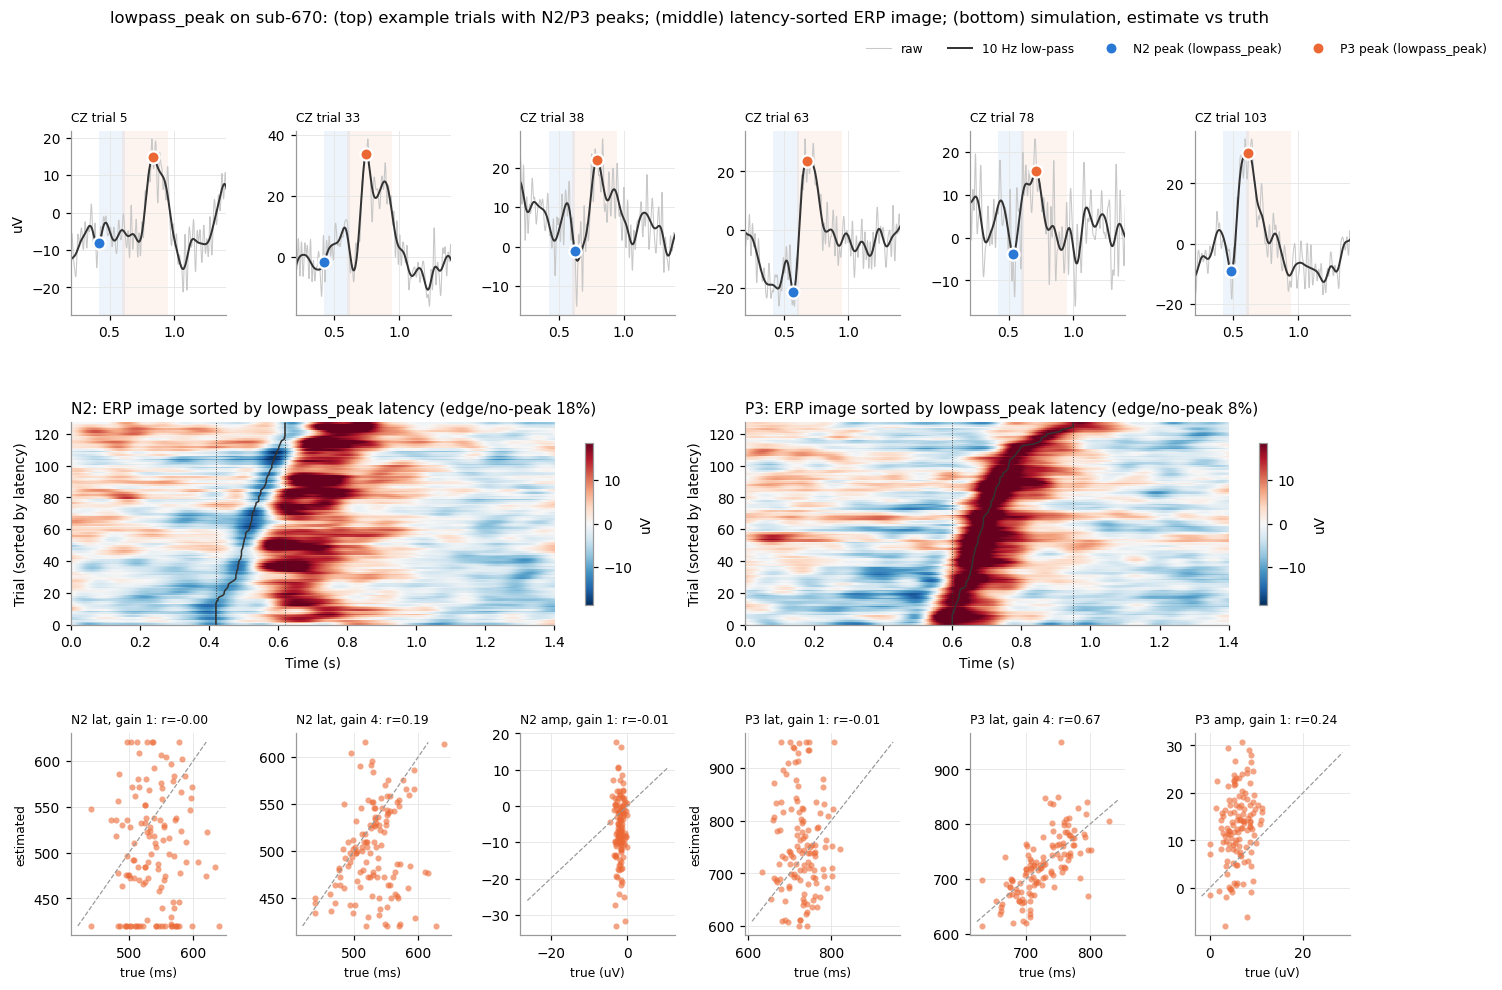

**lowpass_peak - simulation accuracy on sub-670 (one simulated data set per gain)**  
<small>r_lat / r_amp = Pearson r between estimated and true single-trial latency / amplitude (1 = perfect, 0 = chance); rmse_lat_ms = latency error (a constant guess gives about 40 ms).</small>

,component,gain,r_lat,rmse_lat_ms,r_amp
0,N2,1.0,-0.001,80.499,-0.013
1,N2,4.0,0.191,61.650,0.265
2,P3,1.0,-0.014,104.908,0.235
3,P3,4.0,0.674,42.526,0.655


In [9]:
def m_lowpass_peak(X, t, sfreq, comp):
    return window_peak(lowpass(X, sfreq), t, comp)

METHODS['lowpass_peak'] = m_lowpass_peak
show_method('lowpass_peak')

### 5.3 `local_peak`: Luck (2014) local peak

The chosen point must be larger than the mean of the ±20 ms on *both* sides, i.e. a genuine local extreme
and not a point on a slope running into the window border. If no local extreme exists, amplitude falls back
to the window mean and latency is NaN. Compared with `lowpass_peak`, this removes the edge artefact; the
amplitude bias from noise remains.

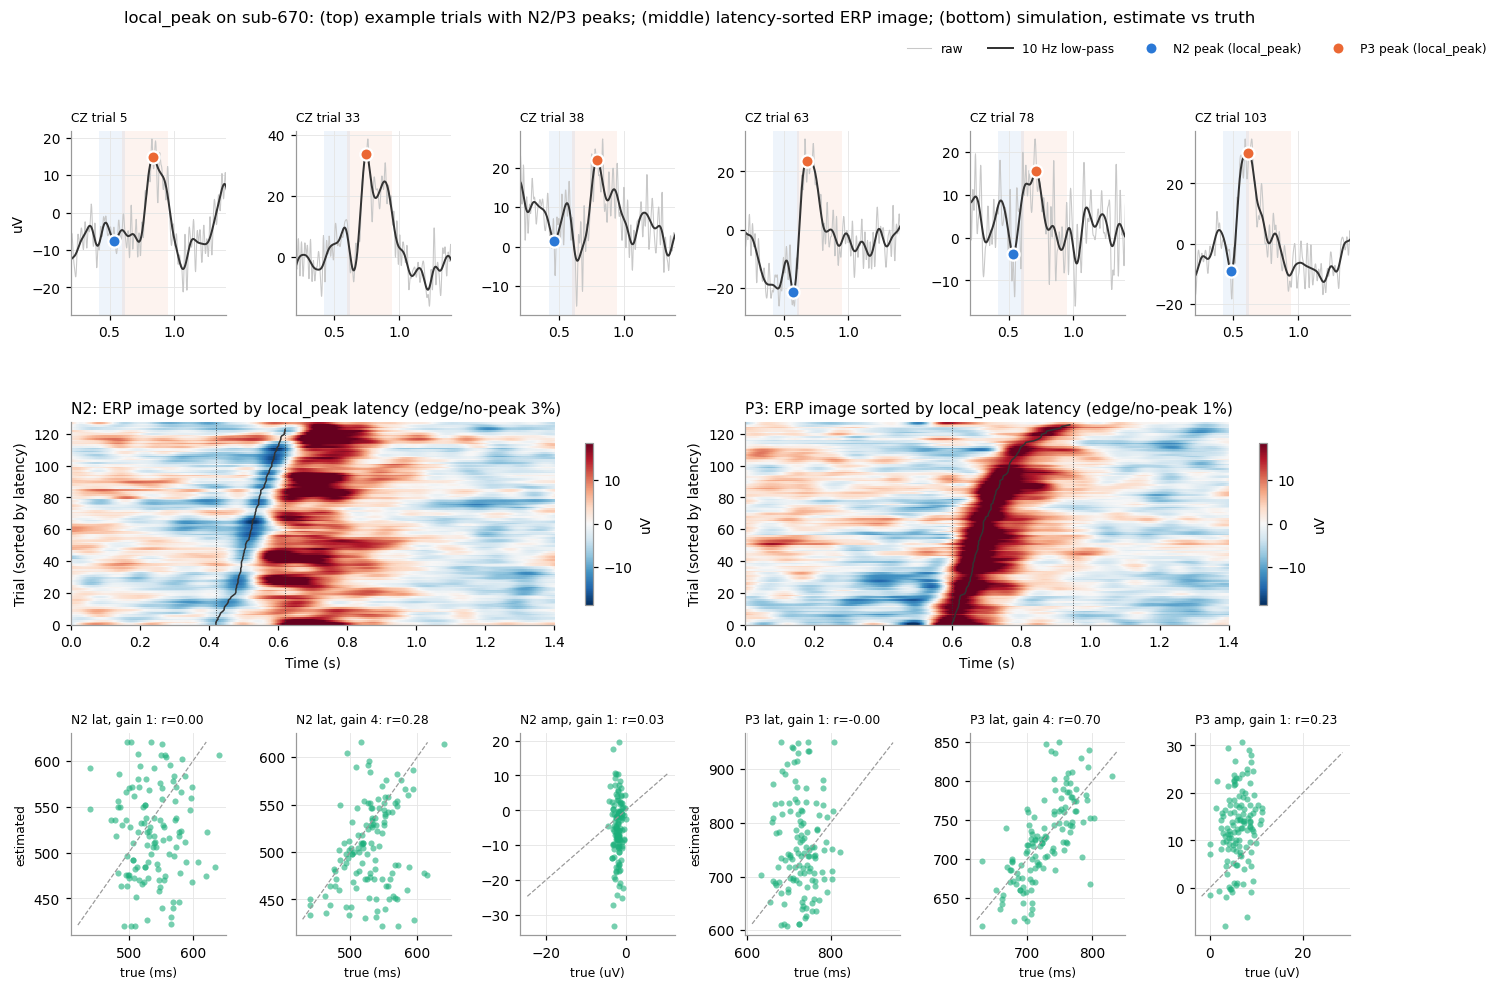

**local_peak - simulation accuracy on sub-670 (one simulated data set per gain)**  
<small>r_lat / r_amp = Pearson r between estimated and true single-trial latency / amplitude (1 = perfect, 0 = chance); rmse_lat_ms = latency error (a constant guess gives about 40 ms).</small>

,component,gain,r_lat,rmse_lat_ms,r_amp
0,N2,1.0,0.002,65.242,0.028
1,N2,4.0,0.281,55.644,0.250
2,P3,1.0,-0.004,101.141,0.227
3,P3,4.0,0.697,38.971,0.655


In [10]:
def m_local_peak(X, t, sfreq, comp, hw=LOCAL_PEAK_HW):
    Y = lowpass(X, sfreq)
    s = comp['sign']
    k = max(1, int(round(hw * sfreq)))
    idx = _win_idx(t, comp['win'])
    n, T = Y.shape
    c = np.concatenate([np.zeros((n, 1)), np.cumsum(Y, 1)], 1)   # c[:, j] = sum(Y[:, :j])
    left = (c[:, idx] - c[:, idx - k]) / k                       # mean of Y[i-k : i]
    right = (c[:, idx + k + 1] - c[:, idx + 1]) / k              # mean of Y[i+1 : i+k+1]
    seg = Y[:, idx]
    cand = (s * seg > s * left) & (s * seg > s * right)
    score = np.where(cand, s * seg, -np.inf)
    kk = score.argmax(1)
    has = np.isfinite(score.max(1))
    rows = np.arange(n)
    return dict(amp=np.where(has, seg[rows, kk], seg.mean(1)),
                lat=np.where(has, t[idx[kk]], np.nan), edge=~has)

METHODS['local_peak'] = m_local_peak
show_method('local_peak')

### 5.4 `FAL50_meanamp`: fractional-area latency + mean amplitude (Kiesel et al., 2008)

* **Latency:** the time at which 50 % of the polarity-rectified area inside the window has accumulated.
* **Amplitude:** the mean amplitude in the window.

Both integrate over the window instead of picking one sample, so they are far less noise-sensitive. Mean
amplitude in particular is unbiased by noise. The trade-off is a pull toward the window centre: on pure
noise the 50 % area point sits mid-window, so latency variance is compressed, and the result depends on the
window choice.

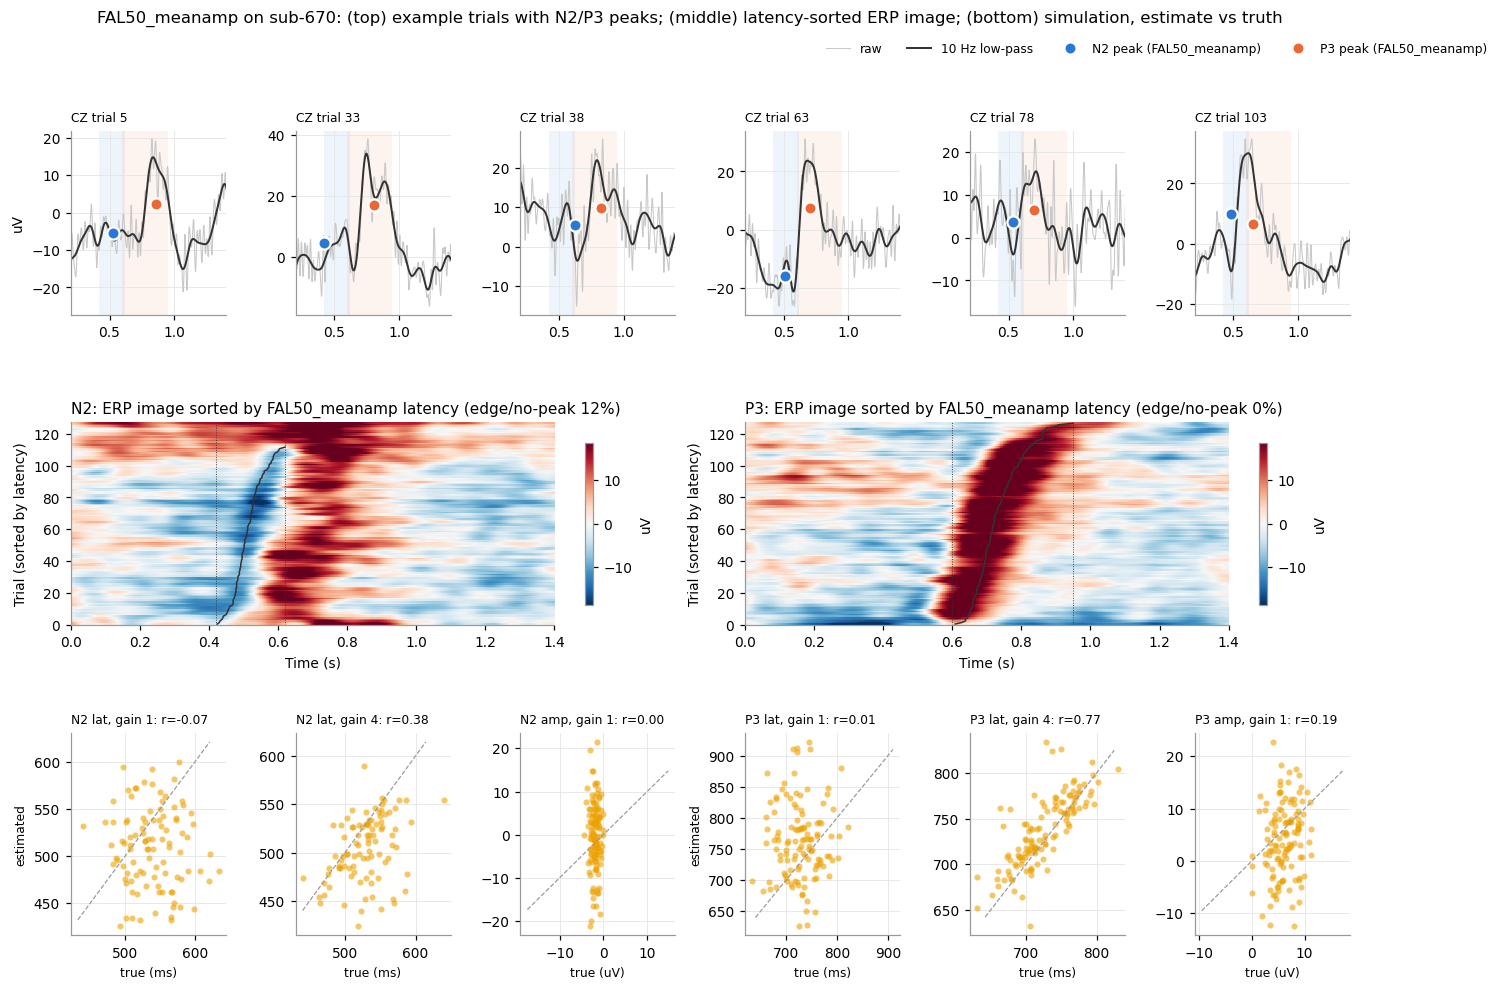

**FAL50_meanamp - simulation accuracy on sub-670 (one simulated data set per gain)**  
<small>r_lat / r_amp = Pearson r between estimated and true single-trial latency / amplitude (1 = perfect, 0 = chance); rmse_lat_ms = latency error (a constant guess gives about 40 ms).</small>

,component,gain,r_lat,rmse_lat_ms,r_amp
0,N2,1.0,-0.067,64.313,0.001
1,N2,4.0,0.378,44.308,0.201
2,P3,1.0,0.014,79.379,0.193
3,P3,4.0,0.771,28.857,0.587


In [11]:
def m_fal_meanamp(X, t, sfreq, comp, frac=FAL_FRAC):
    Y = lowpass(X, sfreq)
    idx = _win_idx(t, comp['win'])
    seg = Y[:, idx]
    pos = np.clip(comp['sign'] * seg, 0, None)
    cum = np.cumsum(pos, 1)
    tot = cum[:, -1]
    kk = (cum >= frac * tot[:, None]).argmax(1)
    return dict(amp=seg.mean(1), lat=np.where(tot > 0, t[idx[kk]], np.nan), edge=tot <= 0)

METHODS['FAL50_meanamp'] = m_fal_meanamp
show_method('FAL50_meanamp')

### 5.5 `wavelet_peak`: wavelet denoising (Quian Quiroga & Garcia, 2003)

Each trial is decomposed with a 6-level DWT (`bior3.3`). The method keeps only coefficients that (i) lie in
bands below 15 Hz, (ii) are centred between 0.3 and 1.3 s, and (iii) have a reliable across-trial mean
(|t| > 2). All other coefficients are set to zero, the trial is reconstructed, and the window peak is taken.

The original paper chose coefficients by eye from the average; the |t| rule automates that. Because selection
is based on the *average*, the denoised trials are pulled toward the average waveform, and with ~100 trials
very few coefficients pass. The reconstruction can then be nearly flat, which pushes the latency to the
window edges. The method works much better with more trials or a looser threshold (`WAV_T_THR`).

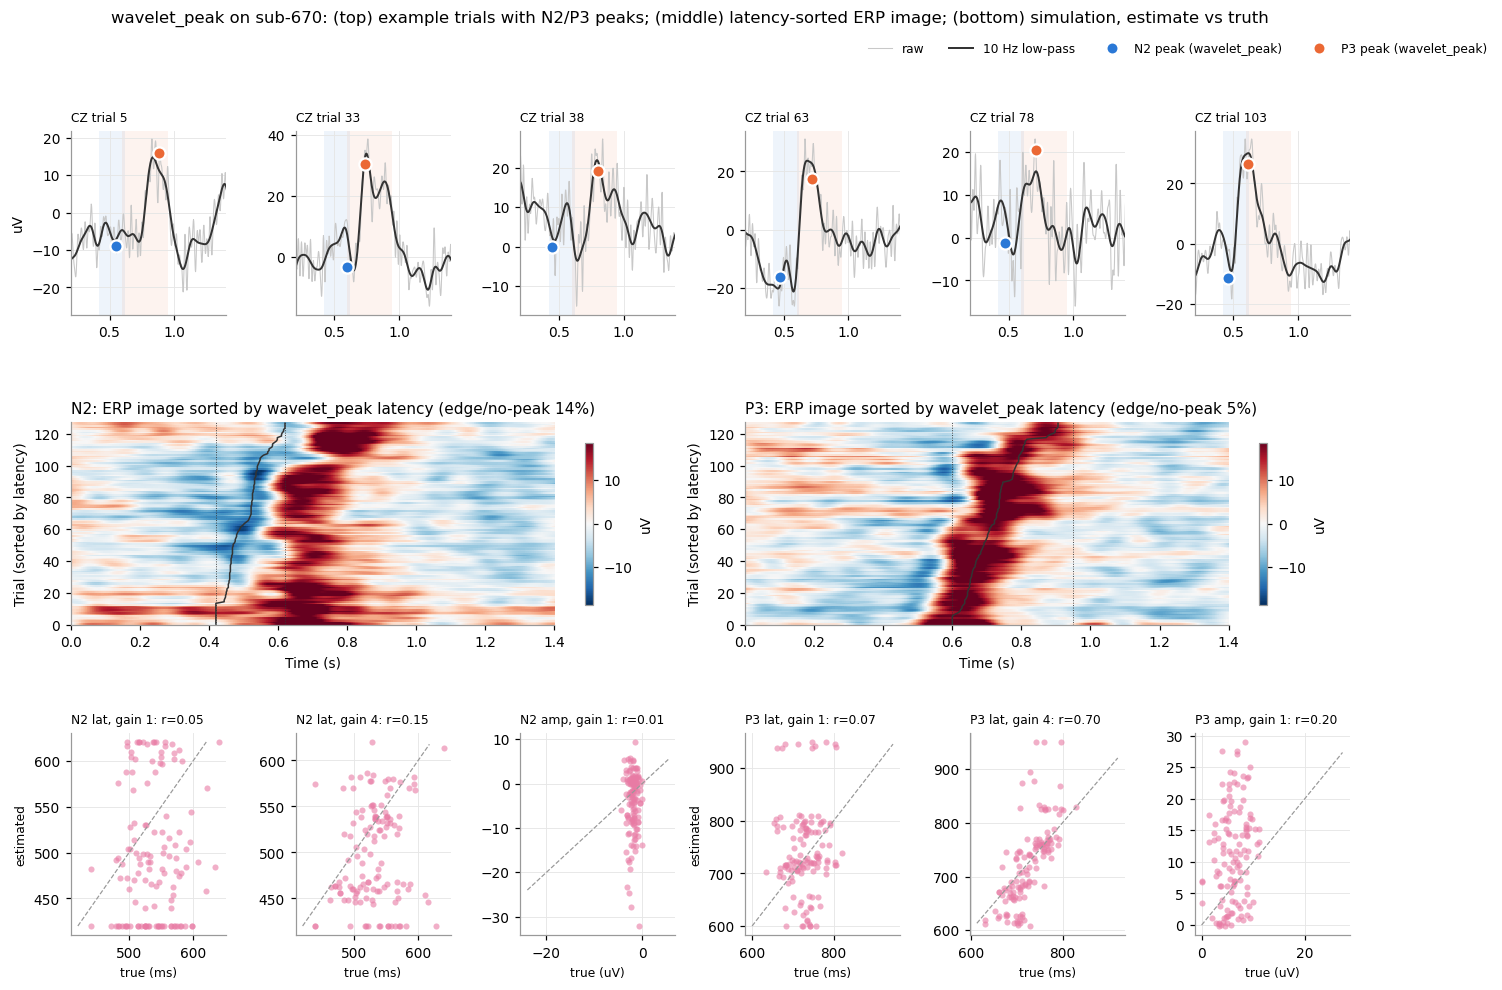

**wavelet_peak - simulation accuracy on sub-670 (one simulated data set per gain)**  
<small>r_lat / r_amp = Pearson r between estimated and true single-trial latency / amplitude (1 = perfect, 0 = chance); rmse_lat_ms = latency error (a constant guess gives about 40 ms).</small>

,component,gain,r_lat,rmse_lat_ms,r_amp
0,N2,1.0,0.048,87.599,0.014
1,N2,4.0,0.153,68.221,0.240
2,P3,1.0,0.074,88.520,0.201
3,P3,4.0,0.703,56.044,0.625


In [12]:
def wavelet_denoise(X, t, sfreq, wavelet=WAV_NAME, max_hz=WAV_MAX_HZ, t_thr=WAV_T_THR, time_win=WAV_TIME_WIN):
    N = X.shape[1]
    level = int(np.ceil(np.log2(sfreq / (2 * 4.0))))  # approximation band <= ~4 Hz (level 6 at 500 Hz)
    coeffs = pywt.wavedec(X, wavelet, mode='periodization', level=level, axis=-1)
    new, n_keep = [], 0
    for j, C in enumerate(coeffs):
        lev = level if j == 0 else level - j + 1
        lo_hz = 0.0 if j == 0 else sfreq / 2 ** (lev + 1)
        if lo_hz >= max_hz:
            new.append(np.zeros_like(C)); continue
        centres = t[0] + (np.arange(C.shape[1]) + 0.5) * (2 ** lev) / sfreq
        in_t = (centres >= time_win[0]) & (centres <= time_win[1])
        tt = np.abs(C.mean(0)) / np.maximum(C.std(0, ddof=1) / np.sqrt(len(C)), 1e-12)
        keep = in_t & (tt > t_thr)
        n_keep += keep.sum()
        new.append(C * keep[None, :])
    if n_keep == 0:  # nothing reliable: keep all low-frequency coefficients in time_win
        return wavelet_denoise(X, t, sfreq, wavelet, max_hz, -np.inf, time_win)
    return pywt.waverec(new, wavelet, mode='periodization', axis=-1)[:, :N]

def m_wavelet_peak(X, t, sfreq, comp):
    return window_peak(wavelet_denoise(X, t, sfreq), t, comp)

METHODS['wavelet_peak'] = m_wavelet_peak
show_method('wavelet_peak')

### 5.6 `woody`: iterative cross-correlation alignment (Woody, 1967)

1. Start from the average (low-passed) waveform inside the window as the template.
2. Find the lag within ±100 ms that maximises each trial's Pearson correlation with the template.
3. Re-average the aligned trials into a new template, and repeat until the lags stop changing.

Latency is the final template's peak time plus the trial's lag; amplitude is the low-passed trial value at
that latency. Correlating a whole waveform segment uses more samples than a single peak. However, at low
SNR the method is known to align noise to the template: the template "finds itself" in noise, so the lags
partly reflect noise, and many trials end at ±max lag (flagged as edge).

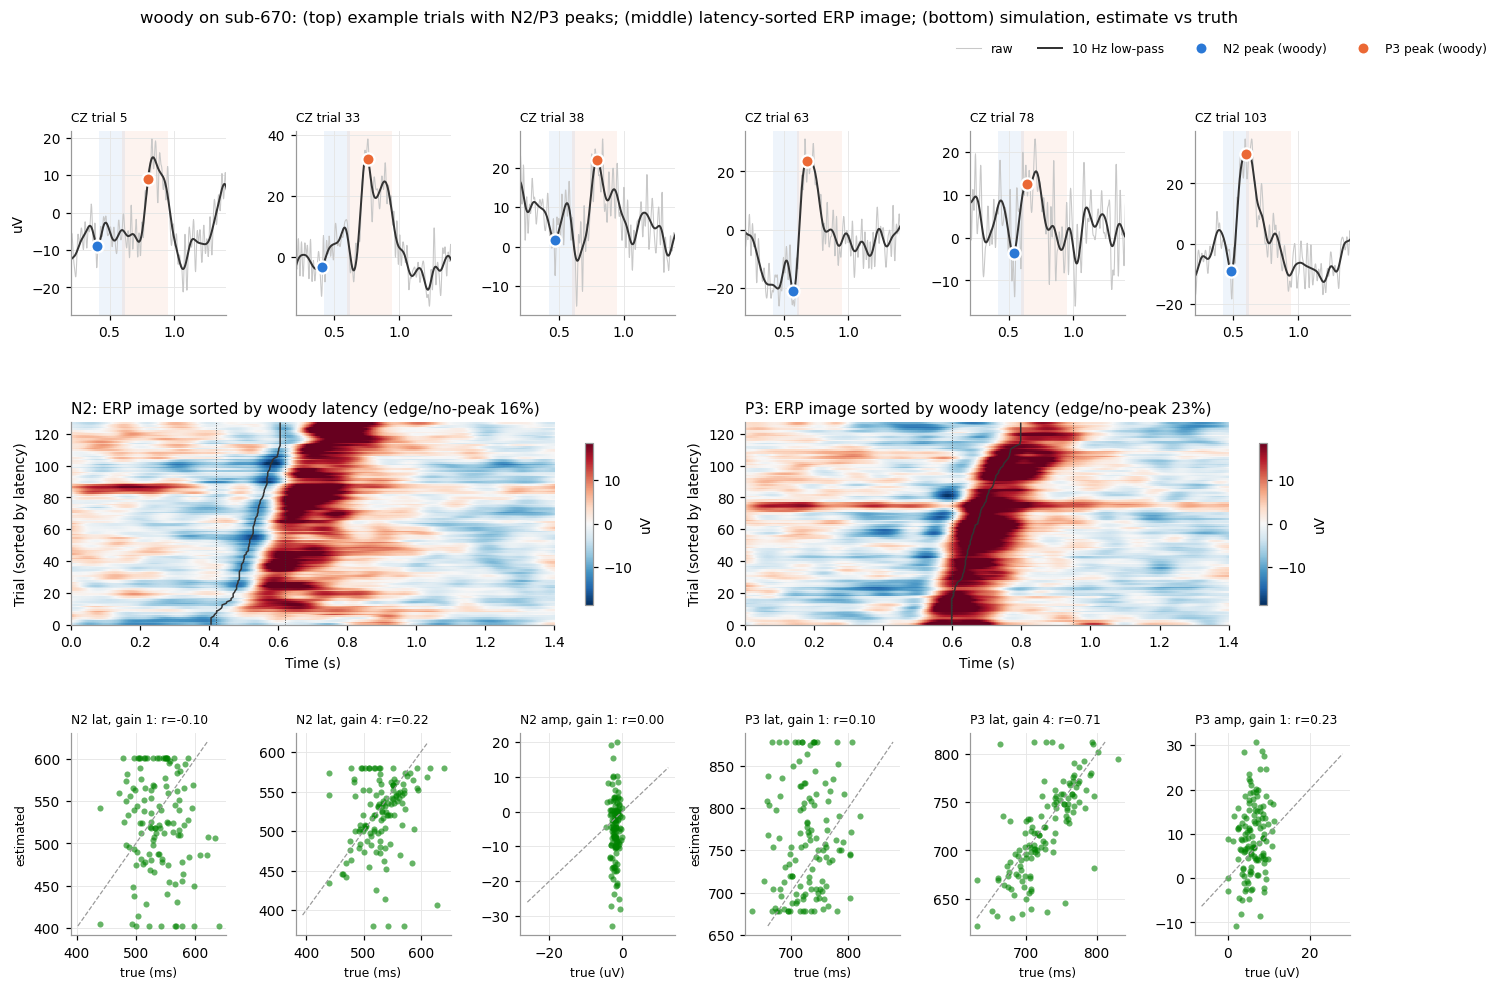

**woody - simulation accuracy on sub-670 (one simulated data set per gain)**  
<small>r_lat / r_amp = Pearson r between estimated and true single-trial latency / amplitude (1 = perfect, 0 = chance); rmse_lat_ms = latency error (a constant guess gives about 40 ms).</small>

,component,gain,r_lat,rmse_lat_ms,r_amp
0,N2,1.0,-0.097,74.836,0.004
1,N2,4.0,0.216,53.556,0.266
2,P3,1.0,0.097,79.071,0.226
3,P3,4.0,0.708,33.937,0.656


In [13]:
def m_woody(X, t, sfreq, comp, max_lag=WOODY_MAX_LAG, n_iter=WOODY_N_ITER):
    Y = lowpass(X, sfreq)
    n = len(Y)
    idx = _win_idx(t, comp['win'])
    L = int(round(max_lag * sfreq))
    lags = np.arange(-L, L + 1)
    seg = np.stack([Y[:, idx + l] for l in lags], 1)               # (n, n_lag, n_win)
    seg_c = seg - seg.mean(-1, keepdims=True)
    seg_n = seg_c / np.maximum(np.linalg.norm(seg_c, axis=-1, keepdims=True), 1e-12)
    lag_i = np.full(n, L)                                          # start at zero lag
    tmpl = Y[:, idx].mean(0)
    rows = np.arange(n)
    for _ in range(n_iter):
        tc = tmpl - tmpl.mean()
        r = seg_n @ (tc / np.linalg.norm(tc))
        new = r.argmax(1)
        tmpl = seg[rows, new].mean(0)
        converged = np.array_equal(new, lag_i)
        lag_i = new
        if converged:
            break
    kp = (comp['sign'] * tmpl).argmax()
    lag_s = lags[lag_i]
    pk = idx[kp] + lag_s
    return dict(amp=Y[rows, pk], lat=t[pk], edge=np.abs(lag_s) == L)

METHODS['woody'] = m_woody
show_method('woody')

### 5.7 `template_MLR`: template + derivative regression (Hu, Mouraux et al., 2010/2011)

Each trial (window ±100 ms) is regressed on four terms: an intercept, the average template T(t), its temporal
derivative T'(t), and a dispersion term (t − t_peak)·T'(t). By first-order Taylor expansion, a·T(t − τ) ≈
a·T − a·τ·T′, so the fit can shift, scale and stretch the template. The single-trial peak is read from the
fitted curve.

Because the fit is constrained to the template's shape, the estimates are smooth and the method uses all the
samples. The cost is that the approximation only holds for small shifts (≲ ¼ period). Trials whose template
weight is ≤ 0 (anti-correlated with the template) are flagged as edge.

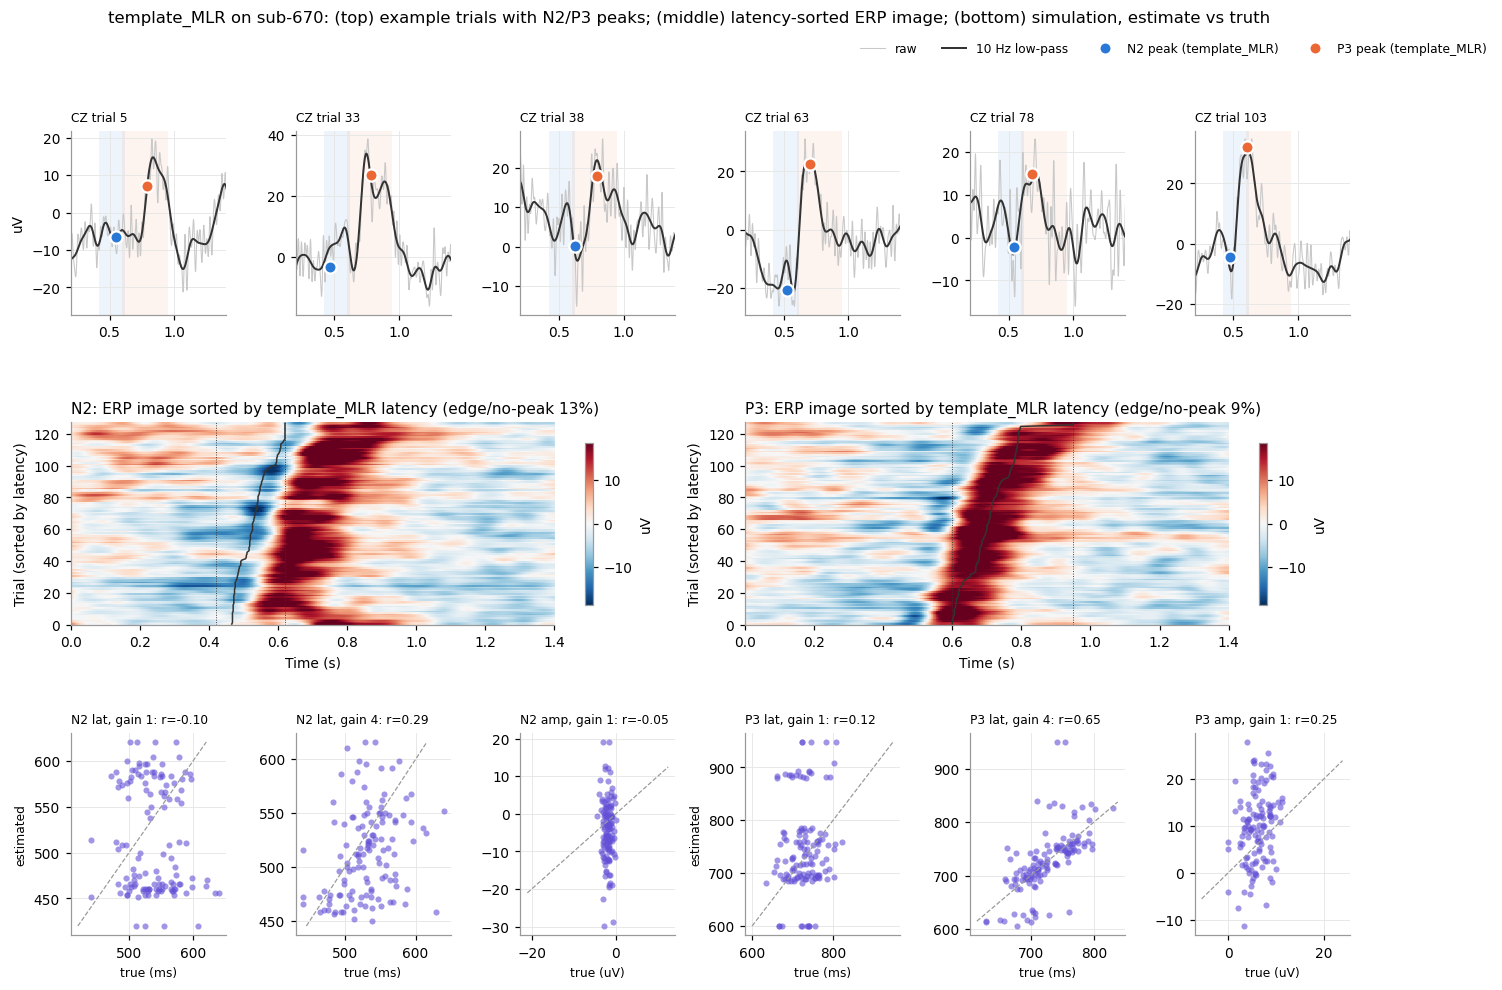

**template_MLR - simulation accuracy on sub-670 (one simulated data set per gain)**  
<small>r_lat / r_amp = Pearson r between estimated and true single-trial latency / amplitude (1 = perfect, 0 = chance); rmse_lat_ms = latency error (a constant guess gives about 40 ms).</small>

,component,gain,r_lat,rmse_lat_ms,r_amp
0,N2,1.0,-0.101,76.690,-0.052
1,N2,4.0,0.286,49.739,0.249
2,P3,1.0,0.121,89.687,0.247
3,P3,4.0,0.649,45.335,0.681


In [14]:
def m_template_mlr(X, t, sfreq, comp, pad=MLR_PAD):
    Y = lowpass(X, sfreq)
    win = comp['win']
    fidx = _win_idx(t, (win[0] - pad, win[1] + pad))
    tf = t[fidx]
    T = Y[:, fidx].mean(0)
    dT = np.gradient(T, 1 / sfreq)
    in_w = (tf >= win[0]) & (tf <= win[1])
    tc = tf[in_w][(comp['sign'] * T[in_w]).argmax()]
    Dm = np.column_stack([np.ones_like(T), T, dT, (tf - tc) * dT])
    B, *_ = np.linalg.lstsq(Dm, Y[:, fidx].T, rcond=None)         # (4, n)
    full = np.full_like(Y, -np.inf * comp['sign'])
    full[:, fidx] = (Dm @ B).T
    res = window_peak(full, t, comp)
    res['edge'] = res['edge'] | (B[1] <= 0)
    return res

METHODS['template_MLR'] = m_template_mlr
show_method('template_MLR')

## 6. Group comparison of all methods

For every subject:

* Estimates on real `mnt_correct` trials, saved trial by trial to `single_trial_estimates.csv.gz`.
* **Real-data metrics.** None of these is a ground truth:
  * window-edge / no-peak rate
  * cross-channel agreement: the same trial estimated at two neighbouring electrodes (N2: Fz–Cz, P3: Cz–Pz).
    Caveat: the electrodes share the mastoid reference and slow background activity, so shared *noise* also
    raises this correlation, especially for amplitude.
  * in-zone vs out-of-zone Cohen's d (exploratory; the downstream use, not a validity check)
  * between-method Spearman agreement
* **Simulation** (ground truth): `SIM_N_REP` repetitions at each gain in `SIM_GAINS`, using this subject's
  background EEG and trial count.

In [15]:
def run_all_methods(X, t, sfreq, comp):
    return {m: f(X.astype(float), t, sfreq, comp) for m, f in METHODS.items()}

rng = np.random.default_rng(RNG_SEED)
trial_rows, real_rows, sim_rows, agree_rows = [], [], [], []
for key_name, D in tqdm(subj_data.items(), desc='estimating'):
    for cname, comp in COMPONENTS.items():
        est = {}
        for ch in dict.fromkeys(comp['chs'] + (comp['primary'],)):
            if ch not in D[EVENT] or len(D[EVENT][ch]['X']) < MIN_TRIALS:
                continue
            d = D[EVENT][ch]
            est[ch] = run_all_methods(d['X'], t, sfreq, comp)
            for m, res in est[ch].items():
                trial_rows.append(pd.DataFrame(dict(
                    subject=key_name, component=cname, channel=ch, method=m, trial_id=d['id'],
                    amp_uV=res['amp'], lat_s=res['lat'], edge_or_nopeak=res['edge'],
                    vtc=d['vtc'], in_zone=d['in_zone'])))
        pch = comp['primary']
        ch_a, ch_b = comp['chs']
        have_pair = ch_a in est and ch_b in est
        if have_pair:
            common, ia, ib = np.intersect1d(D[EVENT][ch_a]['id'], D[EVENT][ch_b]['id'], return_indices=True)
        zone = D[EVENT][pch]['in_zone']
        for m in METHODS:
            res = est[pch][m]
            row = dict(subject=key_name, component=cname, method=m, channel=pch, n_trials=len(res['amp']),
                       edge_rate=np.mean(res['edge']),
                       lat_mean_ms=np.nanmean(res['lat']) * 1000, lat_sd_ms=np.nanstd(res['lat']) * 1000,
                       amp_mean_uV=np.nanmean(res['amp']), amp_sd_uV=np.nanstd(res['amp']),
                       d_amp_in_vs_out=cohens_d(res['amp'], zone), d_lat_in_vs_out=cohens_d(res['lat'], zone))
            if have_pair and len(common) >= MIN_TRIALS:
                row['xch_r_amp'] = _r(est[ch_a][m]['amp'][ia], est[ch_b][m]['amp'][ib])
                row['xch_r_lat'] = _r(est[ch_a][m]['lat'][ia], est[ch_b][m]['lat'][ib])
            real_rows.append(row)
        for q in ['lat', 'amp']:
            C = pd.DataFrame({m: est[pch][m][q] for m in METHODS}).corr(method='spearman')
            agree_rows += [dict(subject=key_name, component=cname, quantity=q, m1=a, m2=b, rho=C.loc[a, b])
                           for a in METHODS for b in METHODS]
        # simulation
        if pch in D[NOISE_EVENT]:
            noise = noise_pool_of(D, pch)
            n_tr = len(D[EVENT][pch]['X'])
            for gain in SIM_GAINS:
                for rep in range(SIM_N_REP):
                    Xs, truth = simulate(noise, t, n_tr, sim_params, gain, rng)
                    tr_ = truth[cname]
                    for m, res in run_all_methods(Xs, t, sfreq, comp).items():
                        err = res['lat'] - tr_['lat']
                        sim_rows.append(dict(subject=key_name, component=cname, method=m, gain=gain, rep=rep,
                                             n_trials=n_tr, r_amp=_r(res['amp'], tr_['amp']),
                                             r_lat=_r(res['lat'], tr_['lat']),
                                             rmse_lat_ms=np.sqrt(np.nanmean(err ** 2)) * 1000,
                                             bias_lat_ms=np.nanmean(err) * 1000,
                                             edge_rate=np.mean(res['edge'])))

trial_df = pd.concat(trial_rows, ignore_index=True)
real_df, sim_df, agree_df = pd.DataFrame(real_rows), pd.DataFrame(sim_rows), pd.DataFrame(agree_rows)
trial_df.to_csv(os.path.join(results_dir, "single_trial_estimates.csv.gz"), index=False)
real_df.to_csv(os.path.join(results_dir, "real_data_metrics_per_subject.csv"), index=False)
sim_df.to_csv(os.path.join(results_dir, "simulation_metrics_per_subject.csv"), index=False)
sim_subj = sim_df.groupby(['subject', 'component', 'method', 'gain'], as_index=False).mean(numeric_only=True)
print(f"{len(trial_df):,} single-trial estimates from {trial_df.subject.nunique()} subjects")

estimating:   0%|          | 0/14 [00:00<?, ?it/s]

estimating:   7%|▋         | 1/14 [00:04<00:53,  4.15s/it]

estimating:  14%|█▍        | 2/14 [00:06<00:40,  3.36s/it]

estimating:  21%|██▏       | 3/14 [00:09<00:32,  2.92s/it]

estimating:  29%|██▊       | 4/14 [00:12<00:30,  3.04s/it]

estimating:  36%|███▌      | 5/14 [00:16<00:29,  3.23s/it]

... (8 outputs left out)

estimating:  93%|█████████▎| 13/14 [00:39<00:02,  2.92s/it]

estimating: 100%|██████████| 14/14 [00:42<00:00,  2.88s/it]

estimating: 100%|██████████| 14/14 [00:42<00:00,  3.02s/it]

34,034 single-trial estimates from 14 subjects


### 6.1 Simulation: how well does each method recover the truth?

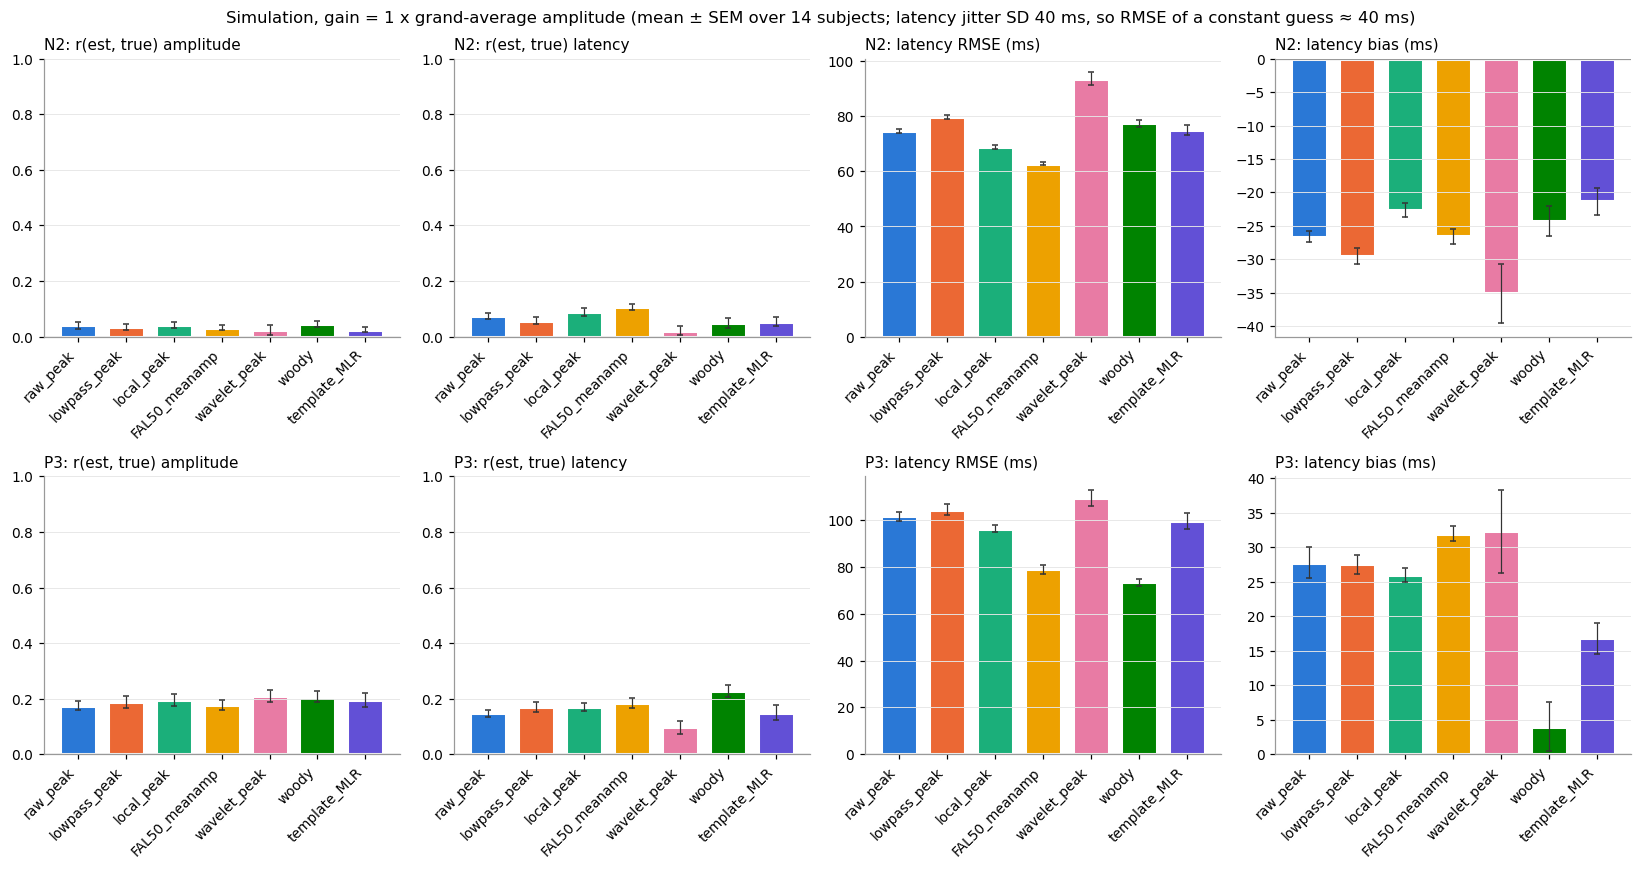

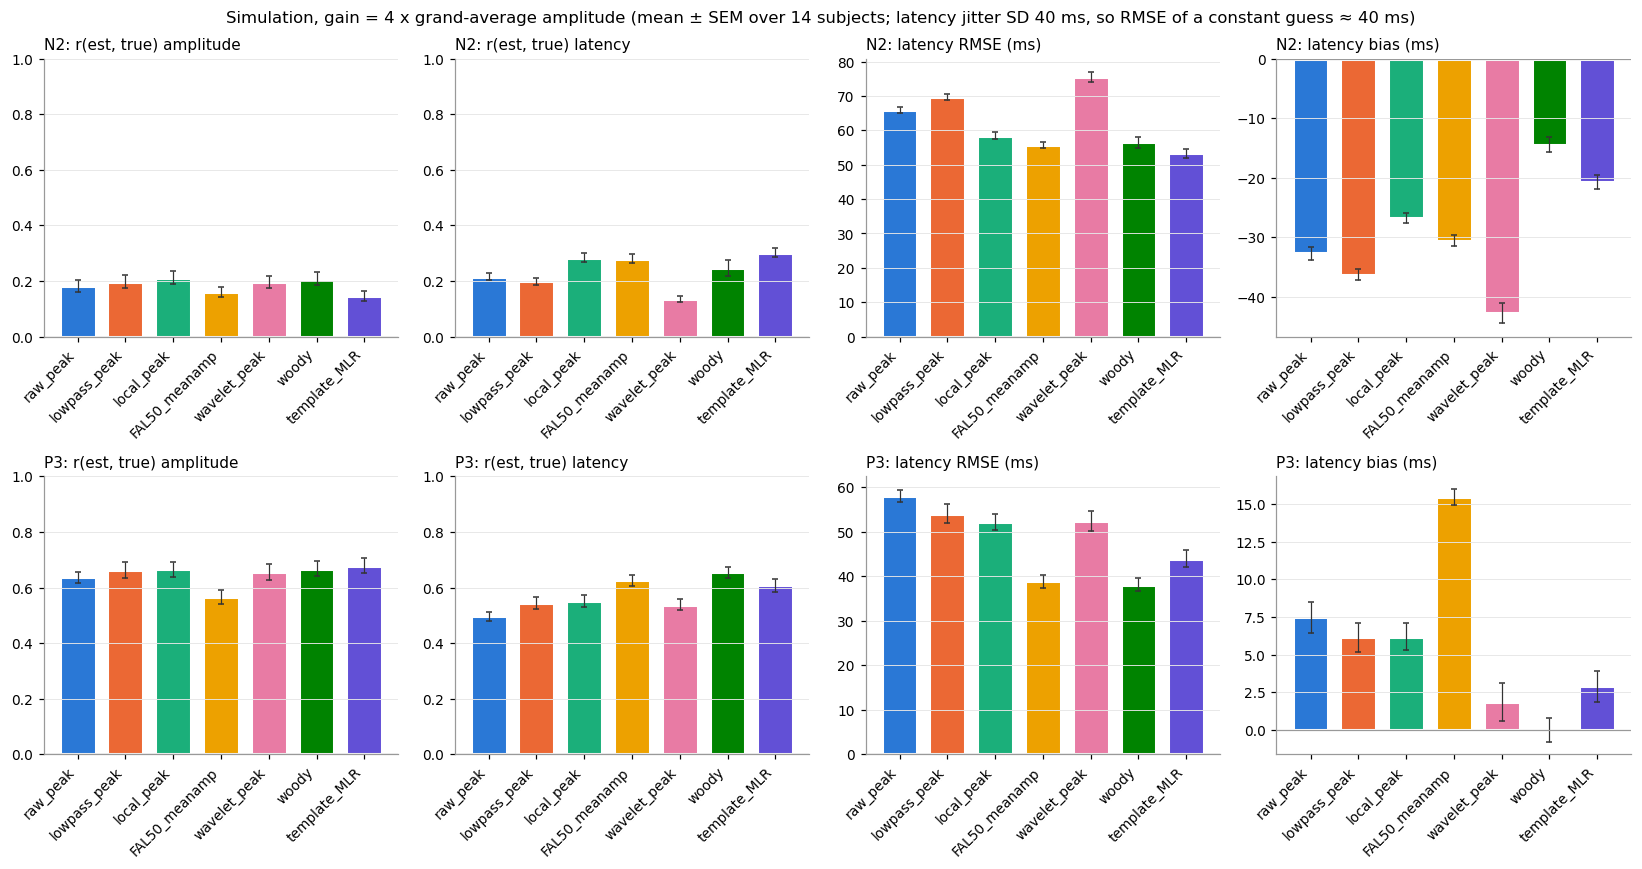

In [16]:
ms = list(METHODS)

def bar_panel(ax, df, metric, title, ylim=None):
    g = df.groupby('method')[metric]
    mean, sem = g.mean().reindex(ms), (g.std() / np.sqrt(g.count())).reindex(ms)
    x = np.arange(len(ms))
    ax.bar(x, mean.values, yerr=sem.values, color=[METHOD_COLORS[m] for m in ms], width=0.75,
           edgecolor='white', linewidth=2, capsize=2, error_kw=dict(ecolor=INK, lw=0.8))
    ax.set_xticks(x); ax.set_xticklabels(ms, rotation=45, ha='right')
    ax.set_title(title, loc='left'); ax.axhline(0, color='#999999', lw=0.8)
    if ylim is not None: ax.set_ylim(*ylim)
    ax.grid(axis='x', visible=False)

for gain in [1.0, 4.0]:
    g = sim_subj[sim_subj.gain == gain]
    fig, axes = plt.subplots(len(COMPONENTS), 4, figsize=(15, 4.0 * len(COMPONENTS)))
    for r_i, cname in enumerate(COMPONENTS):
        sub = g[g.component == cname]
        bar_panel(axes[r_i, 0], sub, 'r_amp', f"{cname}: r(est, true) amplitude", (0, 1))
        bar_panel(axes[r_i, 1], sub, 'r_lat', f"{cname}: r(est, true) latency", (0, 1))
        bar_panel(axes[r_i, 2], sub, 'rmse_lat_ms', f"{cname}: latency RMSE (ms)")
        bar_panel(axes[r_i, 3], sub, 'bias_lat_ms', f"{cname}: latency bias (ms)")
    fig.suptitle(f"Simulation, gain = {gain:g} x grand-average amplitude (mean ± SEM over "
                 f"{g.subject.nunique()} subjects; latency jitter SD {SIM_LAT_SD*1000:.0f} ms, "
                 f"so RMSE of a constant guess ≈ {SIM_LAT_SD*1000:.0f} ms)")
    fig.tight_layout()
    fig.savefig(os.path.join(group_dir, f"simulation_gain{gain:g}.png"), dpi=150, bbox_inches='tight')
    plt.show()

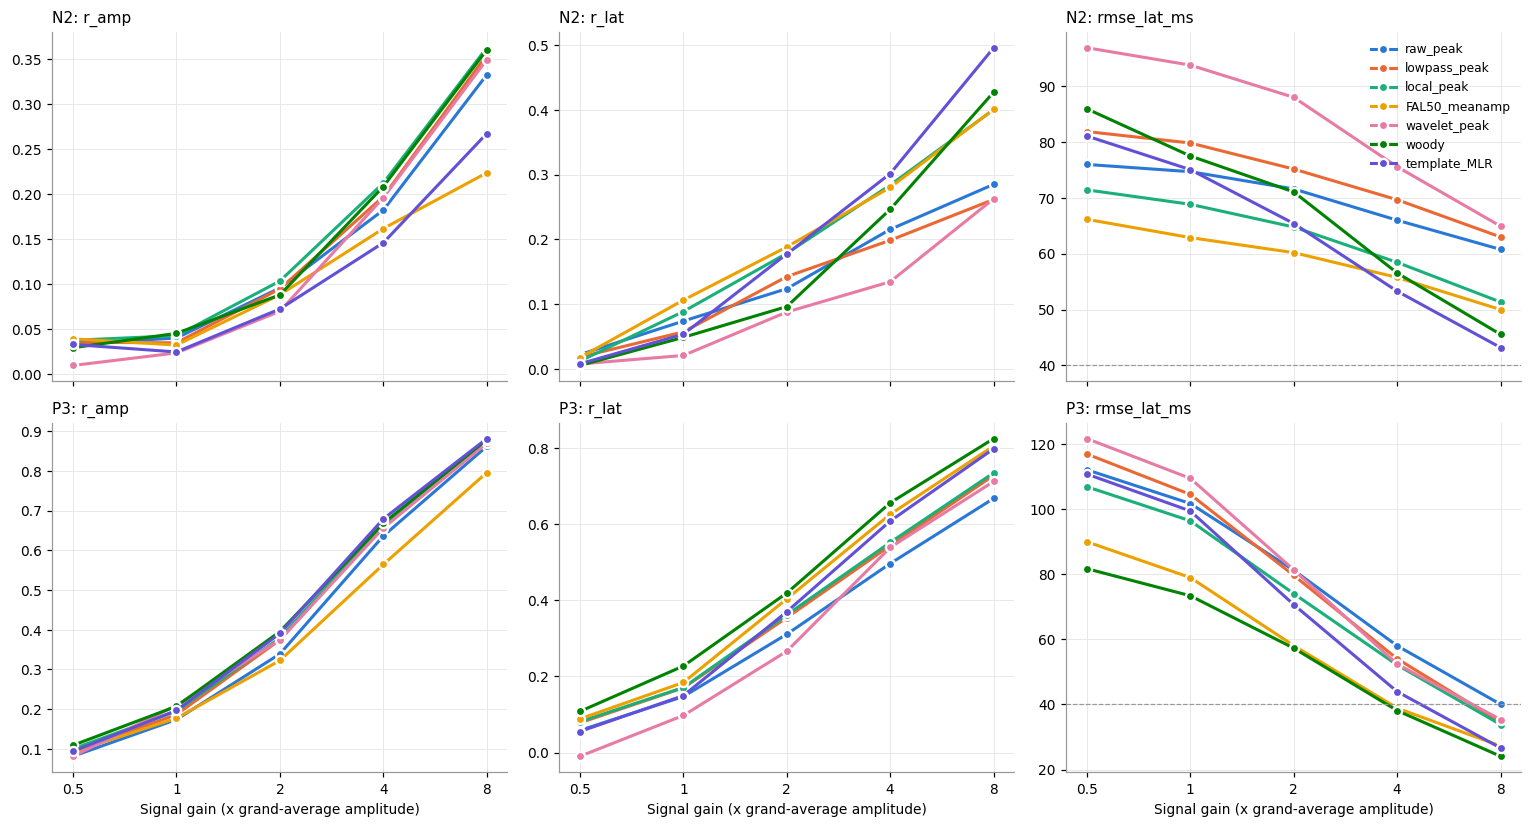

**Table 6.1 - Simulation accuracy of every method, mean over subjects (gain 1 = realistic, gain 4 = 4x stronger signal)**  
<small>r_amp / r_lat = Pearson r(estimate, truth); rmse_lat_ms / bias_lat_ms = latency error and mean signed error (ms); edge_rate = fraction of trials whose peak hit the window border / had no peak. All gains are in summary_simulation.csv.</small>

r_amp  r_lat  rmse_lat_ms  bias_lat_ms  \
component gain method                                                  
N2        1.0  FAL50_meanamp  0.033  0.106       62.871      -26.584   
               local_peak     0.043  0.089       68.826      -22.667   
               lowpass_peak   0.035  0.057       79.789      -29.504   
               raw_peak       0.040  0.074       74.662      -26.613   
               template_MLR   0.025  0.054       75.028      -21.321   
               wavelet_peak   0.024  0.021       93.722      -35.110   
               woody          0.046  0.049       77.470      -24.325   
          4.0  FAL50_meanamp  0.162  0.280       55.747      -30.575   
               local_peak     0.212  0.284       58.441      -26.719   
               lowpass_peak   0.197  0.199       69.640      -36.308   
               raw_peak       0.182  0.215       65.979      -32.739   
               template_MLR   0.146  0.301       53.282      -20.680   
               wavelet_peak   0.196  0.135       75.541      -42.829   
               woody          0.208  0.246       56.544      -14.461   
P3        1.0  FAL50_meanamp  0.177  0.184       78.995       31.921   
               local_peak     0.195  0.171       96.428       25.980   
               lowpass_peak   0.186  0.170      104.548       27.523   
               raw_peak       0.174  0.147      101.747       27.745   
               template_MLR   0.197  0.149       99.466       16.786   
               wavelet_peak   0.210  0.097      109.482       32.282   
               woody          0.207  0.227       73.410        3.995   
          4.0  FAL50_meanamp  0.564  0.625       38.874       15.454   
               local_peak     0.665  0.552       52.153        6.195   
               lowpass_peak   0.663  0.543       54.044        6.143   
               raw_peak       0.636  0.496       58.040        7.469   
               template_MLR   0.679  0.608       43.955        2.884   
               wavelet_peak   0.656  0.538       52.410        1.869   
               woody          0.668  0.656       38.122       -0.006   

                              edge_rate  
component gain method                    
N2        1.0  FAL50_meanamp      0.231  
               local_peak         0.019  
               lowpass_peak       0.211  
               raw_peak           0.068  
               template_MLR       0.348  
               wavelet_peak       0.512  
               woody              0.198  
          4.0  FAL50_meanamp      0.199  
               local_peak         0.016  
               lowpass_peak       0.125  
               raw_peak           0.036  
               template_MLR       0.076  
               wavelet_peak       0.181  
               woody              0.130  
P3        1.0  FAL50_meanamp      0.069  
               local_peak         0.000  
               lowpass_peak       0.095  
               raw_peak           0.031  
               template_MLR       0.254  
               wavelet_peak       0.183  
               woody              0.239  
          4.0  FAL50_meanamp      0.010  
               local_peak         0.000  
               lowpass_peak       0.018  
               raw_peak           0.006  
               template_MLR       0.032  
               wavelet_peak       0.022  
               woody              0.078

In [17]:
fig, axes = plt.subplots(len(COMPONENTS), 3, figsize=(14, 3.8 * len(COMPONENTS)), sharex=True)
for r_i, cname in enumerate(COMPONENTS):
    for c_i, metric in enumerate(['r_amp', 'r_lat', 'rmse_lat_ms']):
        ax = axes[r_i, c_i]
        for m in ms:
            agg = sim_subj[(sim_subj.component == cname) & (sim_subj.method == m)].groupby('gain')[metric].mean()
            ax.plot(agg.index, agg.values, '-o', color=METHOD_COLORS[m], lw=2, ms=6, mec='white', mew=1.5, label=m)
        if metric == 'rmse_lat_ms':
            ax.axhline(SIM_LAT_SD * 1000, color='#999999', ls='--', lw=0.8)
        ax.set_xscale('log', base=2); ax.set_xticks(SIM_GAINS); ax.set_xticklabels([f"{g:g}" for g in SIM_GAINS])
        ax.set_title(f"{cname}: {metric}", loc='left')
        if r_i == len(COMPONENTS) - 1: ax.set_xlabel('Signal gain (x grand-average amplitude)')
axes[0, -1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(group_dir, "simulation_vs_gain.png"), dpi=150, bbox_inches='tight')
plt.show()

summary_sim = sim_subj.groupby(['component', 'gain', 'method'])[
    ['r_amp', 'r_lat', 'rmse_lat_ms', 'bias_lat_ms', 'edge_rate']].mean().round(3)
summary_sim.to_csv(os.path.join(group_dir, "summary_simulation.csv"))
show_table(summary_sim.loc[(slice(None), [1.0, 4.0]), :],
           'Table 6.1 - Simulation accuracy of every method, mean over subjects (gain 1 = realistic, gain 4 = 4x stronger signal)',
           'r_amp / r_lat = Pearson r(estimate, truth); rmse_lat_ms / bias_lat_ms = latency error and mean signed error (ms); '
           'edge_rate = fraction of trials whose peak hit the window border / had no peak. All gains are in summary_simulation.csv.')

### 6.2 Real `mnt_correct` data

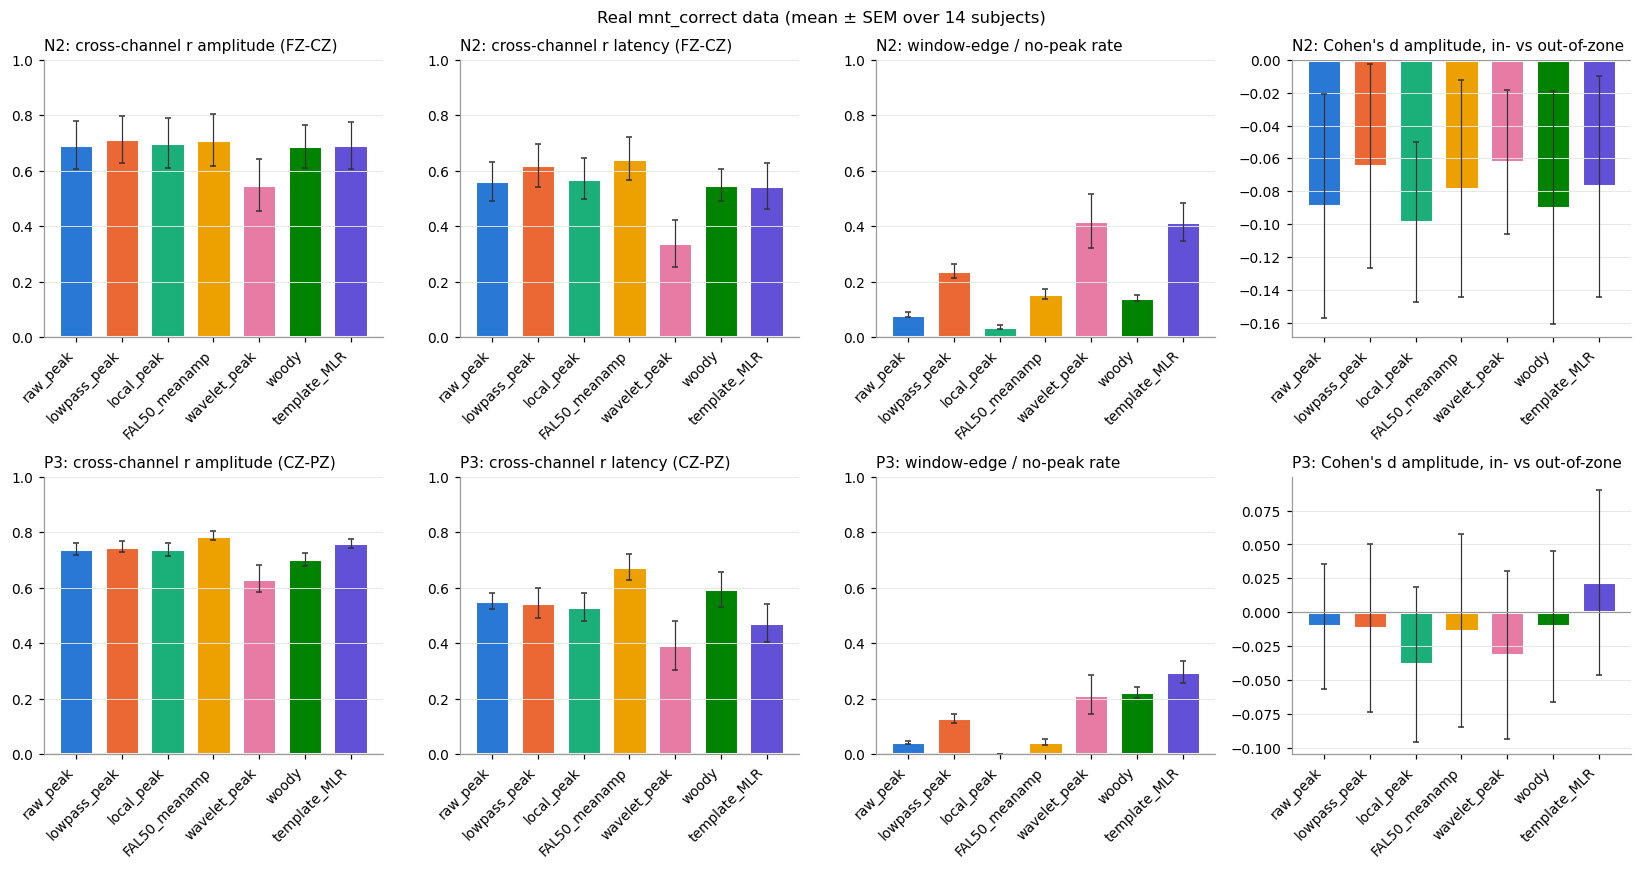

**Table 6.2 - Real mnt_correct data: metrics of every method, mean over subjects (primary channel)**  
<small>xch_r_amp / xch_r_lat = same-trial correlation between neighbouring electrodes (inflated by shared noise); edge_rate = border / no-peak rate; lat_mean_ms, lat_sd_ms, amp_mean_uV = distribution of the estimates; d_* = Cohen d, in-zone minus out-of-zone.</small>

xch_r_amp  xch_r_lat  edge_rate  lat_mean_ms  \
component method                                                        
N2        FAL50_meanamp      0.711      0.644      0.156      526.294   
          local_peak         0.701      0.572      0.037      524.497   
          lowpass_peak       0.714      0.620      0.238      528.304   
          raw_peak           0.693      0.563      0.081      527.309   
          template_MLR       0.692      0.545      0.415      530.083   
          wavelet_peak       0.549      0.339      0.418      502.811   
          woody              0.688      0.549      0.142      530.344   
P3        FAL50_meanamp      0.788      0.676      0.043      769.076   
          local_peak         0.738      0.532      0.001      758.417   
          lowpass_peak       0.748      0.545      0.129      759.957   
          raw_peak           0.740      0.553      0.043      761.705   
          template_MLR       0.761      0.473      0.295      754.176   
          wavelet_peak       0.632      0.393      0.215      767.735   
          woody              0.703      0.595      0.223      745.398   

                         lat_sd_ms  amp_mean_uV  d_amp_in_vs_out  \
component method                                                   
N2        FAL50_meanamp     47.365       -0.442           -0.078   
          local_peak        55.579       -9.204           -0.099   
          lowpass_peak      65.512      -10.698           -0.065   
          raw_peak          60.319      -17.244           -0.089   
          template_MLR      62.125       -7.589           -0.077   
          wavelet_peak      59.975       -5.273           -0.062   
          woody             58.481       -8.845           -0.090   
P3        FAL50_meanamp     68.598        4.246           -0.014   
          local_peak        90.107       16.129           -0.038   
          lowpass_peak      97.398       16.835           -0.012   
          raw_peak          94.848       23.432           -0.010   
          template_MLR      85.313       12.401            0.022   
          wavelet_peak      97.407       12.724           -0.031   
          woody             64.740       13.249           -0.010   

                         d_lat_in_vs_out  
component method                          
N2        FAL50_meanamp            0.066  
          local_peak               0.067  
          lowpass_peak             0.017  
          raw_peak                 0.058  
          template_MLR             0.052  
          wavelet_peak            -0.117  
          woody                   -0.043  
P3        FAL50_meanamp           -0.071  
          local_peak              -0.080  
          lowpass_peak            -0.075  
          raw_peak                -0.118  
          template_MLR            -0.087  
          wavelet_peak             0.051  
          woody                   -0.158

In [18]:
fig, axes = plt.subplots(len(COMPONENTS), 4, figsize=(15, 4.0 * len(COMPONENTS)))
for r_i, (cname, comp) in enumerate(COMPONENTS.items()):
    sub = real_df[real_df.component == cname]
    pair = f"{comp['chs'][0].upper()}-{comp['chs'][1].upper()}"
    bar_panel(axes[r_i, 0], sub, 'xch_r_amp', f"{cname}: cross-channel r amplitude ({pair})", (0, 1))
    bar_panel(axes[r_i, 1], sub, 'xch_r_lat', f"{cname}: cross-channel r latency ({pair})", (0, 1))
    bar_panel(axes[r_i, 2], sub, 'edge_rate', f"{cname}: window-edge / no-peak rate", (0, 1))
    bar_panel(axes[r_i, 3], sub, 'd_amp_in_vs_out', f"{cname}: Cohen's d amplitude, in- vs out-of-zone")
fig.suptitle(f"Real {EVENT} data (mean ± SEM over {real_df.subject.nunique()} subjects)")
fig.tight_layout(); fig.savefig(os.path.join(group_dir, "real_data_metrics.png"), dpi=150, bbox_inches='tight')
plt.show()

summary_real = real_df.groupby(['component', 'method'])[
    ['xch_r_amp', 'xch_r_lat', 'edge_rate', 'lat_mean_ms', 'lat_sd_ms', 'amp_mean_uV',
     'd_amp_in_vs_out', 'd_lat_in_vs_out']].mean().round(3)
summary_real.to_csv(os.path.join(group_dir, "summary_real_data.csv"))
show_table(summary_real,
           f'Table 6.2 - Real {EVENT} data: metrics of every method, mean over subjects (primary channel)',
           'xch_r_amp / xch_r_lat = same-trial correlation between neighbouring electrodes (inflated by shared noise); '
           'edge_rate = border / no-peak rate; lat_mean_ms, lat_sd_ms, amp_mean_uV = distribution of the estimates; '
           'd_* = Cohen d, in-zone minus out-of-zone.')

### 6.3 Between-method agreement (real data, primary channel)

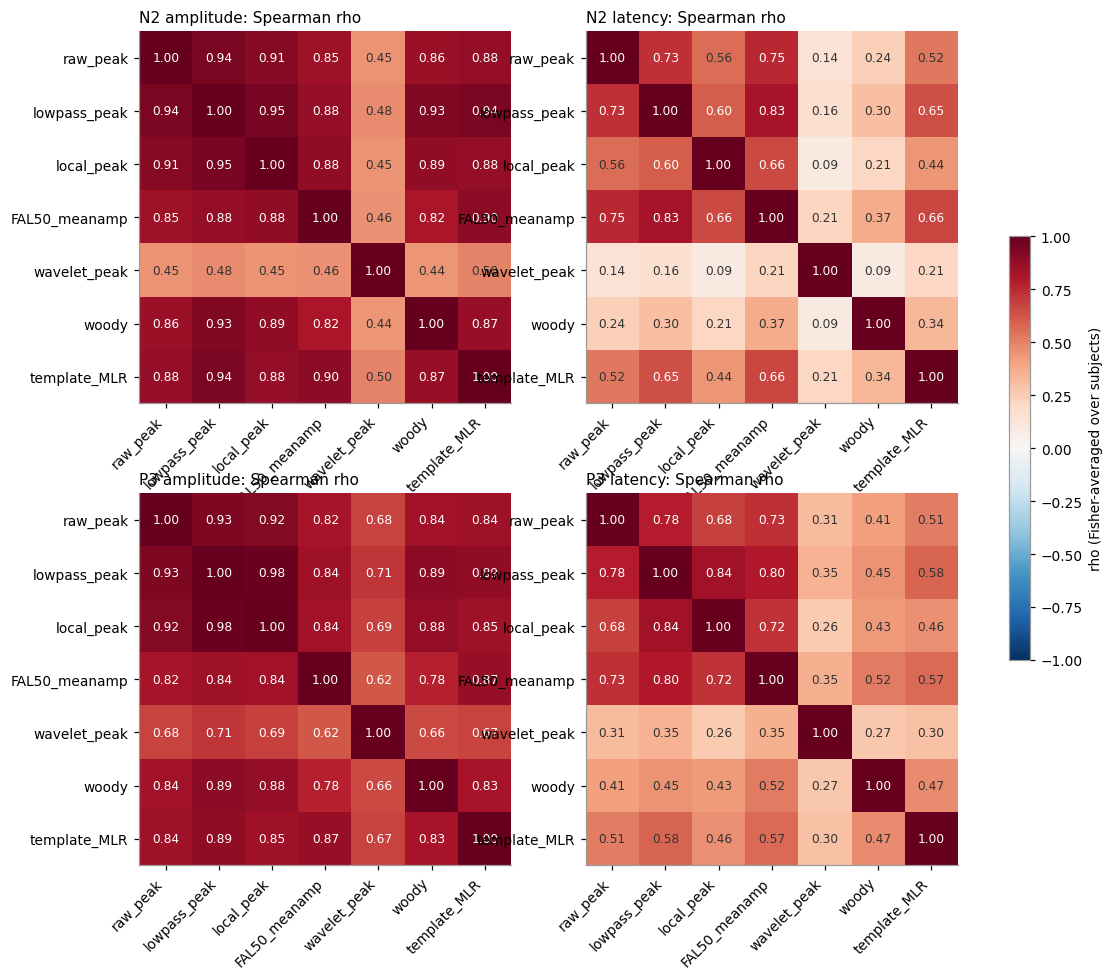

In [19]:
fig, axes = plt.subplots(len(COMPONENTS), 2, figsize=(12, 5.0 * len(COMPONENTS)))
for r_i, cname in enumerate(COMPONENTS):
    for c_i, q in enumerate(['amp', 'lat']):
        ax = axes[r_i, c_i]
        sub = agree_df[(agree_df.component == cname) & (agree_df.quantity == q)]
        M = np.array([[_fisher_mean(sub[(sub.m1 == a) & (sub.m2 == b)].rho) for b in ms] for a in ms])
        im = ax.imshow(M, cmap='RdBu_r', vmin=-1, vmax=1)
        for i in range(len(ms)):
            for j in range(len(ms)):
                ax.text(j, i, f"{M[i, j]:.2f}", ha='center', va='center', fontsize=8,
                        color='white' if abs(M[i, j]) > 0.6 else INK)
        ax.set_xticks(range(len(ms))); ax.set_xticklabels(ms, rotation=45, ha='right')
        ax.set_yticks(range(len(ms))); ax.set_yticklabels(ms); ax.grid(False)
        ax.set_title(f"{cname} {'amplitude' if q == 'amp' else 'latency'}: Spearman rho", loc='left')
fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.5, label='rho (Fisher-averaged over subjects)')
fig.savefig(os.path.join(group_dir, "between_method_agreement.png"), dpi=150, bbox_inches='tight')
plt.show()

## 7. Summary (run of 2026-11-04, 14 subjects, 57–127 `mnt_correct` trials at Cz)

**0. Epoch alignment check (section 2.1).** The city vs mountain ERP reproduces `xSubj_analysis_ERP_ERSP.py`.
Mountain trials show an N2 dip around 550 ms and a P3 of about +6 µV at Cz peaking around 720–750 ms (larger
at Pz); city trials stay flat. An earlier version of this notebook used misaligned events: the July change in
`gen_EEG_event_tsv` read the trigger as a (1, n) array, which set the trigger offset to 0 s. That is fixed
in `utils.py`.

**1. Single-trial SNR (Table 3.2, Cz):**

| Component | Subject-average peak | Single-trial background SD | SNR |
|---|---|---|---|
| P3 | ≈ +7.8 µV | ≈ 11 µV | ≈ 0.76 |
| N2 | ≈ −2.3 µV | ≈ 11 µV | ≈ 0.18 |

**2. Realistic gain (1×), Table 6.1:**
* **P3:** single-trial amplitude is weakly recoverable, with r(est, truth) = 0.17–0.21 for every method.
  Latency is weaker: r = 0.10–0.23, with `woody` best (0.23) and `FAL50_meanamp` next (0.18). Latency RMSE
  (73–109 ms) is still worse than guessing the mean latency (≈ 40 ms).
* **N2:** not recoverable (all r ≤ 0.11).

**3. Ranking when there is more signal (gain 4×):**
* P3 latency: `woody` (r 0.66, RMSE 38 ms, no bias) ≈ `FAL50_meanamp` (0.63, 39 ms) > `template_MLR` (0.61)
  > `local_peak` / `lowpass_peak` / `wavelet_peak` (≈ 0.54) > `raw_peak` (0.50).
* P3 amplitude: `template_MLR`, `woody`, `local_peak` and `lowpass_peak` are about equal (r ≈ 0.66–0.68), with
  `raw_peak` lower (0.64) and the window mean (`FAL50`) lowest (0.56).
* N2 stays poor even at 4× (r ≤ 0.30); `template_MLR`, `local_peak` and `FAL50` are best.

**4. Biases of peak picking:**
* Amplitude inflation: `raw_peak` gives a mean single-trial P3 of +23 µV and N2 of −17 µV, against an ERP of
  +7.8 / −2.3 µV. The maximum of noise always looks like a big peak. Low-pass and local-peak reduce this but
  do not remove it.
* Latency bias: estimates are pulled toward the window centre and edges. The N2 bias is −20 to −35 ms; the P3
  bias is +17 to +32 ms for every method except `woody`, which is about 0.

**5. Real data (Table 6.2).** Cross-channel latency agreement (Cz–Pz) is highest for `FAL50_meanamp` (0.68)
and `woody` (0.60), which agrees with the simulation ranking. Amplitude agreement is ≥ 0.7 for every method,
partly from shared noise, so it is not a reliability measure on its own. In-zone vs out-of-zone effects are
small for every method (|d| < 0.12).

**Recommendation**
* **P3:** use `woody` or `FAL50_meanamp` for latency, and `template_MLR`, `woody` or `local_peak` for amplitude,
  rather than `raw_peak`. Expect single-trial reliability of about r ≈ 0.2: only aggregate analyses (regressions
  over many trials, or binned / sliding averages) will be meaningful, and slopes will be attenuated.
* **N2:** do not interpret single-trial N2 at this SNR. Use mean amplitude in the window, or trial averages.
